# Inverse model python notebook 

This code has been adapted from the Xiaozhou Ruan code provided in matlab, and has been switched into python. 
Primarily, the code has been changed to better fit with the Palmer 2007 CTD data from the Amundsen Sea, which my hydrography had previously working with. 

The code comes from Ruan matlab code and my previous hydrography work from Palmer_data_version3. I have adapted other's code, written code, and in some places used Claude to edit the code. This work is not complete and likely has errors. 


### Notes 
James cruise JR165: 
- This is the cruise data used in Ruan 2021, from the Bellingshausen Sea 
- JR165: 253 stations/94,613 rows; palmer: 190 stations/146,918 rows
- The james cruise data has been combined into one long dataframe for easier processing
- jr165_ctd_long.pkl — 94,613 rows, 253 stations, columns station/lat/lon/pres/potemp/salin/oxy
- vertical spacing of 2 m 

Palmer cruise NBP 0702: 
- The Amundsen sea data used in previous hydrographic study I did 
- palmer_nbp0702_ctd_long.pkl — 146,918 rows, 190 stations, same columns, built from the palmer NBP0702 netCDF files
- vertical spacing of 1 m 




## Imports 

In [59]:
from pathlib import Path
import numpy as np
import gsw 
from pyproj import Geod
import matplotlib.pyplot as plt
import pandas as pd
import re
import netCDF4 as nc
import xarray as xr 

DATA_DIR = Path.cwd().resolve().parent

# Functions 

#### load in ctd datasets

In [60]:
james_table_path = DATA_DIR / "jr165_ctd_long.pkl"
palmer_table_path = DATA_DIR / "palmer_nbp0702_ctd_long.pkl"

print("JR165 combined table:", james_table_path)
print("palmer combined table:", palmer_table_path)

james_ctd = pd.read_pickle(james_table_path) 
palmer_ctd = pd.read_pickle(palmer_table_path)

JR165 combined table: /home/edworak/Notebooks/Bells_inverse_model_edited/jr165_ctd_long.pkl
palmer combined table: /home/edworak/Notebooks/Bells_inverse_model_edited/palmer_nbp0702_ctd_long.pkl


# Data processing functions

#### bottom triangles 

In [61]:
"""
Bottom triangle, following Thompson and Heywood (2008)
- the bottom triangle is between the shallow station A's deepest point and the deeper station B's deepest point
- returns the triangle's row range and width profile that tapers to 0 
- vel_inverse splices the tapered width into area_matrix, and width averages v_tri in the tracer budget in inverse_solver()
"""

def bottom_triangle(shallow_bottom_row, deep_bottom_row, pair_dist_m):
    if deep_bottom_row <= shallow_bottom_row:
        # both stations reach the same depth -- no triangle
        return np.array([], dtype=int), np.array([])

    tri_rows = np.arange(shallow_bottom_row + 1, deep_bottom_row + 1)

    # taper the inter-station distance to 0 at deeper pair bottom 
    weight_shallow = (deep_bottom_row - tri_rows) / (deep_bottom_row - shallow_bottom_row)
    dist_tri_profile = pair_dist_m * weight_shallow

    return tri_rows, dist_tri_profile


###  Vel inverse universal 

Tiny read me: vel_inverse 
- function takes in 'sec_num' and returns all local variables through 'return locals()'
- return locals() returns a dictionary containing all local variables from within the function 
- keys are variable names as strings, values connected to variable 

In [62]:
# sec_num is section number
def vel_inverse(df_ctd, sec_num, adj_table=None, extra_bumps=None, vel2_for_sec_nums=(3, 4), dz=None, station_list=None, latlon=None, inflow=None):

    geod = Geod(ellps="WGS84")  # for true per-pair bearing (bearing-honest sign, see below)

    # keep depth index deeper than any real station
    depth_idx = 5000
    depth_range = int(depth_idx/dz)

    # station_list: array of station numbers for this section, doesn't have to be sequential or sorted
    stations = np.asarray(station_list)
    df_ctd_unique = df_ctd.drop_duplicates(subset=['station'], keep='first').set_index('station')
    lon = np.asarray(df_ctd_unique.loc[stations, "lon"], dtype=float)
    lat = np.asarray(df_ctd_unique.loc[stations, "lat"], dtype=float)

    # create array of zeros of length of n stations in section
    n = len(stations)
    mask = np.zeros(n)

    potemp = np.zeros((depth_range, n))
    salin = np.zeros((depth_range, n))
    oxy = np.zeros((depth_range, n))
    p = np.ones((depth_range, n))
    pres = p * np.arange(0, depth_idx, dz).reshape(-1, 1) # reshaped to ctd sampling if dz=2

    for i in range(0, n):
        ctd_station = df_ctd[df_ctd["station"] == stations[i]].sort_values("pres")
        # need to trim data to real pressure levels (palmer doesnt always start at 0)
        # alternative option is to interpolate to surface

        real_pres = ctd_station["pres"].to_numpy()
        T = np.asarray(ctd_station["potemp"], dtype=float).ravel() #.ravel() will flatten a multidimensional array to 1D
        S = np.asarray(ctd_station["salin"], dtype=float).ravel()
        O = np.asarray(ctd_station["oxy"], dtype=float).ravel()

        row_idx = np.round(np.real((real_pres - 1) / dz)).astype(int)   # nearest common-grid row for each real sample
        valid = (row_idx >= 0) & (row_idx < depth_range)

        potemp[row_idx[valid], i] = T[valid]
        salin[row_idx[valid], i] = S[valid]
        oxy[row_idx[valid], i] = O[valid]
        mask[i] = int(row_idx[valid].max()) + 1 if valid.any() else 0


    # set 0 values to nan (if no data available, like too deep)
    mask = mask.astype(int)
    potemp[potemp == 0] = np.nan
    salin[salin == 0] = np.nan
    oxy[oxy == 0] = np.nan
    # gsw.rho needs SA/CT, convert p=pres for SA_from_SP (tiny correction term),
    # p=0 for gsw.rho itself to be a potential density referenced to the surface, matching sw_dens(salin, potemp, 0)
    SA = gsw.SA_from_SP(salin, pres, lon[np.newaxis, :], lat[np.newaxis, :])
    CT = gsw.CT_from_pt(SA, potemp)
    # pden = gsw.rho(SA, CT, 0) - 1000

    """Velocity calculation
    - svan: specific volume anomaly in seawater
    - dB_SPascal: constant value to translate pressure in decibars to pascals bc its better for height variations
    """
    svan = gsw.specvol_anom_standard(SA, CT, pres)

    dB_SPascal = 1e4
    mean_svan = 0.5 * (svan[1:, :] + svan[:-1, :])

    # extract the pressure range in pascals
    # svan shows subtle horizontal pressure-gradient and ssh/isobar height variation
    # A change of 1 Hectopascal (hPa = 100 Pascals) translates to a 1-centimeter change in sea level
    # need to convert for geopotential anomaly

    # need to calculate the top boundary at sea surface separately
    top = np.zeros(n)
    for i in range(n):
        top[i] = svan[0, i] * pres[0, i] * dB_SPascal

    # delta_ga: the geopotential anomaly increment between two adjacent pressure levels
    # diff(pres) pressure-step width (2 dbar, since the CTD is sampled every 2 dbar) for James 
    delta_ga = (mean_svan * np.diff(pres, axis=0)) * dB_SPascal

    stacked_top = np.vstack([top, delta_ga])

    # ga : geopotential anomaly, the total geopotential anomaly down each column
    # this is still referenced to the surface here - re-referenced to each station's bottom below
    ga = np.cumsum(np.nan_to_num(stacked_top, nan=0.0), axis=0)

    # mask ga values beneath real bottom of column
    for i in range(ga.shape[1]):
        ga[mask[i] :, i] = np.nan

    # extend ga below each station's own real bottom, holding its last value constant
    ga_filled = ga.copy()
    for i in range(n):
        ga_filled[mask[i] :, i] = ga_filled[mask[i] - 1, i]

    # change ordering of stations 
    # every per-pair quantity (azimuth,velocity, triangle rows/widths, area) is derived once in final column order
    if lon[-1] - lon[0] < 0:
        lon = np.flipud(lon)
        lat = np.flipud(lat)
        mask = np.flipud(mask)
        ga_filled = np.fliplr(ga_filled)

    # NOTE: this is dynamical method using geopotential anomaly
    # vel = gsw.geostrophic_velocity(geo_str,long,lat,p), returns (velocity, mid_lon, mid_lat)
    # computes vel = +diff(ga)/(dist*f)
    # v = -Δ(ga between adjacent stations) / (f · distance between them)

    # get the line along station pairs (azimuth) then get perpendicular flow project into the box direction 
    inflow_resolved = inflow if inflow is not None else ("east" if latlon == "lat" else "north")
    ref_vec = {"east": (1, 0), "west": (-1, 0), "north": (0, 1), "south": (0, -1)}.get(inflow_resolved)
    if ref_vec is None:
        raise ValueError(f"inflow must be None, 'east', 'west', 'north', or 'south', got {inflow!r}")
    ref_east, ref_north = ref_vec

    p_axis = pres[:, 0]  # same physical pressure grid for every column

    # Reference each station pair at deep bottom, do seperately for each station
    vel = np.full((depth_range, n - 1), np.nan)
    tri_rows_list = [np.array([], dtype=int)] * (n - 1)
    dist_tri_profile_list = [np.array([])] * (n - 1)
    ref_row_list = [0] * (n - 1)  # each pair's own deep-bottom row, reused below to cut off area_matrix
    v_tri_raw = np.zeros(n - 1)
    for i in range(n - 1):
        az_ab, _, _ = geod.inv(lon[i], lat[i], lon[i + 1], lat[i + 1])
        theta = np.radians(az_ab)
        projection = np.cos(theta) * ref_east - np.sin(theta) * ref_north

        ref_row = max(mask[i], mask[i + 1]) - 1  # ref row at deep bottom
        ref_row_list[i] = ref_row
        ga_pair = ga_filled[:, i : i + 2] - ga_filled[ref_row, i : i + 2]

        v_pair, _mid_lon, _mid_lat = gsw.geostrophic_velocity(ga_pair, lon[i : i + 2], lat[i : i + 2], pres[:, i : i + 2])
        vel[:, i] = - v_pair[:, 0] * projection
        vel[ref_row + 1 :, i] = np.nan  # no data below either station's real reach

        # bottom triangle for this pair, following Thompson and Heywood (2008) with tapered width 
        pair_bottom_row = min(mask[i], mask[i + 1]) - 1  # shallower station's bottom
        deep_bottom_row = max(mask[i], mask[i + 1]) - 1  # deeper station's bottom
        pair_dist_m = gsw.distance(lon[[i, i + 1]], lat[[i, i + 1]])[0] # taper the width in bottom triangle 

        tri_rows, dist_tri_profile = bottom_triangle(pair_bottom_row, deep_bottom_row, pair_dist_m)

        tri_rows_list[i] = tri_rows
        dist_tri_profile_list[i] = dist_tri_profile

        if len(tri_rows) > 0:
            # width-weighted average of velocity in bottom triangle, used for tracer budget 
            total_width = np.sum(dist_tri_profile)
            v_tri_raw[i] = np.sum(vel[tri_rows, i] * dist_tri_profile) / total_width if total_width > 0 else 0.0
        else:
            v_tri_raw[i] = 1e-6

    vel2 = vel.copy()
    vel3 = vel.copy()

    cal = adj_table[sec_num] # calibration 
    high_count_arr = vel3 if cal["high_count_src"] == "vel3" else vel
    low_count_arr = vel3 if cal["low_count_src"] == "vel3" else vel2

    # keep v_tri on the same reference level so the bottom-triangle contribution and the main-column
    # contribution to the box budget share a calibration
    cal_offset = cal["vel2_offset"] if sec_num in vel2_for_sec_nums else cal["vel3_offset"]
    v_tri = v_tri_raw + cal_offset

    for i in range(vel2.shape[1]):
        cnt2 = int(np.sum(~np.isnan(vel2[:, i])))
        # offset the whole profile by a depth-constant offset, set the top/bottom velocity to be a specific amount
        vel2[:, i] = vel2[:, i] - vel[cnt2 - 1, i] + cal["vel2_offset"]

        # checks if the station has good data past 150 levels / 300 dbar: sets 300 dbar LNM?
        # averages 3 points 148:151 as the anchor
        if int(np.sum(~np.isnan(vel[:, i]))) > 150:
            vel3[:, i] = vel3[:, i] - np.nanmean(high_count_arr[148:151, i]) + cal["vel3_offset"]
        # shallower pairs use the bottom most point directly as anchor/offset point
        else:
            cnt3 = int(np.sum(~np.isnan(low_count_arr[:, i])))
            vel3[:, i] = vel3[:, i] - vel[cnt3 - 1, i] + cal["vel3_offset"]

    # combined velocity profile for the normal depth range and the bottom triangle
    # v_full is a continuous surface-to-bottom profile, covers bottom triangle 
    vel_full_source = vel2 if sec_num in vel2_for_sec_nums else vel3
    v_full = vel_full_source.copy()
    vel1 = vel.copy()

    # manual adjustments to other velocity components
    if extra_bumps:
        arrs = {"vel2": vel2, "vel3": vel3}
        for arr_name, col, offset in extra_bumps:
            arrs[arr_name][:, col] = arrs[arr_name][:, col] + offset

    # pair distance
    dist = np.zeros(lon.shape[0])
    DIST_m = gsw.distance(lon, lat)
    DIST = DIST_m / 1000  # convert meters to km
    dist[1:] = np.cumsum(DIST)

    # take midpoint values of station pair
    lat_new = 0.5 * (lat[:-1] + lat[1:])
    lon_new = 0.5 * (lon[:-1] + lon[1:])
    dist_km = 0.5 * (dist[:-1] + dist[1:])

    # area calculation - down to each pair's real+triangle bottom (ref_row)
    area_matrix = np.zeros((depth_range, len(lon) - 1))
    for i in range(len(lon) - 1):
        ref_row = ref_row_list[i]
        area_matrix[: ref_row + 1, i] = DIST[i] * 1e3 * dz # meters^2

    # add shrinking area for bottom triangles 
    for i in range(len(lon) - 1):
        tri_rows = tri_rows_list[i]
        if len(tri_rows) > 0:
            area_matrix[tri_rows, i] = dist_tri_profile_list[i] * dz

    # transport is just being calculated as velocity * area (depth-width)
    transport1 = np.nansum(vel1 * area_matrix, axis=0)
    transport2 = np.nansum(vel2 * area_matrix, axis=0)
    transport3 = np.nansum(vel3 * area_matrix, axis=0)

    # adjustable v selection for multiple sections
    if sec_num in vel2_for_sec_nums:
        v = vel2
    else:
        v = vel3

    return locals()


# Tracer inverse 

Tiny read me: tracer_inverse 

- load in temperature, salinity and oxygen 
- order arrays correctly based on station sections 
- add in information for the bottom triangles 
- assume sec_num variable as a function input to follow matlab script style 
- output all local variables with return locals() to pull out any needed information 

In [63]:
def tracer_inverse(df_ctd, sec_num, dz = None, station_list=None):

    depth_idx = 5000 
    depth_range = int(depth_idx/dz)

    # station_list: in-order array of station numbers for this section 
    stations = np.asarray(station_list)
    df_ctd_unique = df_ctd.drop_duplicates(subset=['station'], keep='first').set_index('station')
    lon = np.asarray(df_ctd_unique.loc[stations, "lon"], dtype=float)
    lat = np.asarray(df_ctd_unique.loc[stations, "lat"], dtype=float)

    n = len(stations)

    potemp = np.zeros((depth_range, n))
    salin = np.zeros((depth_range, n))
    oxy = np.zeros((depth_range, n))
    p = np.ones((depth_range, n))
    pres = p * np.arange(0, depth_idx, dz).reshape(-1, 1) # reshaped to ctd sampling dz=2 

    # create array of zeros of length of n stations in section 
    mask = np.zeros(n)
    mask_T = np.zeros(n)
    mask_S = np.zeros(n)
    mask_O = np.zeros(n)

    for i in range(0, n):
        ctd_station = df_ctd[df_ctd["station"] == stations[i]].sort_values("pres")
        real_pres = ctd_station["pres"].to_numpy()
        T = np.asarray(ctd_station["potemp"], dtype=float)
        S = np.asarray(ctd_station["salin"], dtype=float)
        O = np.asarray(ctd_station["oxy"], dtype=float)

        row_idx = np.round((real_pres) / dz).astype(int)   # nearest common-grid row for each real sample
        valid = (row_idx >= 0) & (row_idx < depth_range)

        potemp[row_idx[valid], i] = T[valid]
        salin[row_idx[valid], i] = S[valid]
        oxy[row_idx[valid], i] = O[valid]
        mask[i] = int(row_idx[valid].max()) + 1 if valid.any() else 0
        mask_T[i] = int(row_idx[valid].max()) + 1 if valid.any() else 0
        mask_S[i] = int(row_idx[valid].max()) + 1 if valid.any() else 0
        mask_O[i] = int(row_idx[valid].max()) + 1 if valid.any() else 0


    mask = mask.astype(int)
    mask_T = mask_T.astype(int)
    mask_S = mask_S.astype(int)
    mask_O = mask_O.astype(int)

    # set 0 values to nan (if no data available, like too deep)
    potemp[potemp == 0] = np.nan
    salin[salin == 0] = np.nan
    oxy[oxy == 0] = np.nan
    # pden = sw_dens(salin, potemp, 0) - 1000

    # gsw.rho needs SA and CT, not practical salinity / potential temperature straight from the CTD files
    # p=pres :in-situ pressure, use for SA_from_SP
    # p=0 for gsw.rho is potential density referenced to the surface, matches sw_dens(salin, potemp, 0) 

    # np.newaxis is used to increase the dimension of an existing NumPy array by adding a new axis of size 1
    SA = gsw.SA_from_SP(salin, pres, lon[np.newaxis, :], lat[np.newaxis, :])
    CT = gsw.CT_from_pt(SA, potemp)
    pden = gsw.rho(SA, CT, 0) - 1000

    # change ordering of stations
    # XXX: would it be more efficient to switch to classic index flipping m[::-1, :] etc.? 
    if lon[-1] - lon[0] < 0:
        lon = np.flipud(lon) #flipud will flip an array vertically along 0-axis, like m[::-1, :] 
        lat = np.flipud(lat)
        mask = np.flipud(mask)
        mask_T = np.flipud(mask_T) 
        mask_S = np.flipud(mask_S)
        mask_O = np.flipud(mask_O)
        CT = np.fliplr(CT) #fliplr will do horizontal left/right flip along 1-axis, like m[:, ::-1]
        SA = np.fliplr(SA)
        oxy = np.fliplr(oxy)
        pden = np.fliplr(pden)

    dist = np.zeros((lon.shape[0], 1))

    # DIST, _phaseangle = sw_dist(lat, lon, "km")
    DIST_m = gsw.distance(lon, lat)
    DIST = DIST_m / 1000  # convert meters to km

    # take midpoint value of station pair 
    new_SA = 0.5 * (SA[:, :-1] + SA[:, 1:])
    new_CT = 0.5 * (CT[:, :-1] + CT[:, 1:])
    new_oxy = 0.5 * (oxy[:, :-1] + oxy[:, 1:])

    # get an average number of the tracer for the bottom triangle
    CT_tri = np.zeros(n - 1)
    SA_tri = np.zeros(n - 1)
    O_tri = np.zeros(n - 1)

    for i in range(n - 1):
        mask_i = int(mask[i])
        mask_ip1 = int(mask[i + 1])
        # common level of deepest point between two stations 
        comm_lev = min(mask_i, mask_ip1)
        if mask_i > mask_ip1:
            CT_tri[i] = np.nanmean(CT[comm_lev - 1 : mask_i, i])
            SA_tri[i] = np.nanmean(SA[comm_lev - 1 : mask_i, i])
            O_tri[i] = np.nanmean(oxy[comm_lev - 1 : mask_i, i])
        elif mask_i < mask_ip1:
            CT_tri[i] = np.nanmean(CT[comm_lev - 1 : mask_ip1, i + 1])
            SA_tri[i] = np.nanmean(SA[comm_lev - 1 : mask_ip1, i + 1])
            O_tri[i] = np.nanmean(oxy[comm_lev - 1 : mask_ip1, i + 1])
        else:
            # any non-nan number will be fine since the area is zero 
            CT_tri[i] = 1e-6
            SA_tri[i] = 1e-6
            O_tri[i] = 1e-6


    return locals()

# Inverse solver

Note: 
- if you only have A and B for T, S, O then the degree of freedom of v_ref is being used to constrain zero tracer transport beneath the reference depth level (set initially as 200 m) 
- they set the level at 200 m since it is below the ekman layer and is a better representation of the water that comes into contact with the iceshelf cavities 
- this code was built to balance meltwater-relative tracer content 


- I can change the code to also conserve volume by adding an additional constraint, would still include a small non-zero meltwater volume input 
- the code is currently solving for a v_ref for each station pair, becomes a very underdeterminded problem when volume conservation is strictly enforced 
- in the future, could switch code to solve for one v_ref for each section, this would make it simpler and better determined with less sensitivity to each station pair but may remove some needed variability 


<span style="color:pink">
- Either solve for zero volume transport or solve for meltwater tracer volume flux 

</span>

In [64]:
# combine any number of sections into a closed box
# Needed for Palmer boxes where the transects don't follow sequential station numbers

def inverse_solver(df_ctd, sections, adj_table=None, extra_bumps=None, vel2_for_sec_nums=(1,), dz=None, ref_depth=200, inflow_table=None):

    # sections = (section1, section2, ...): station-number arrays, each in along-track
    # order not necessarily sorted by station number
    n_sections = len(sections)

    # ADJ_TABLE_SECTION2/EXTRA_BUMPS_SECTION2 (main()'s defaults) are James JR165-specific --
    # default instead to a neutral, zero-offset calibration covering every section label used
    if adj_table is None:
        adj_table = {
            k: {"vel2_offset": 0.0, "vel3_offset": 0.0, "high_count_src": "vel3", "low_count_src": "vel3"}
            for k in range(1, n_sections + 1)}

    if extra_bumps is None:
        extra_bumps = {}

    # per-section velocity sign convention: which direction counts as "into the box" for each section
    # fallback that each section is organized mostly by latitude or longitude 
    # these three defaults are a guess from the box geometry (Shelf along the top, West and East as the side boundaries)
    if inflow_table is None:
        inflow_table = {
            1: {"latlon": "lat", "inflow": "south"},  # Shelf: box interior is south 
            2: {"latlon": "lon", "inflow": "east"},   # West: box interior is east 
            3: {"latlon": "lon", "inflow": "west"},   # East: box interior is west
            }

    # per-section containers, filled one section at a time below
    T_sec_list, S_sec_list, O_sec_list = [], [], []
    T_tri_sec_list, S_tri_sec_list, O_tri_sec_list = [], [], []
    mask_sec_list, distance_sec_list = [], []
    area_tri_sec_list, V_sec_list, v_tri_sec_list, area_sec_list, v_full_sec_list = [], [], [], [], []
    lat_new_sec_list, lon_new_sec_list = [], []  # per-pair midpoint lat/lon, for pair_df below
    n_sec = []  # pair count per section - needed to split V_tot/V_ref back up later

    for i, section in enumerate(sections):
        sec_num = i + 1
        ds = tracer_inverse(df_ctd, sec_num, dz=dz, station_list=section)

        T_sec_list.append(ds["new_CT"])
        S_sec_list.append(ds["new_SA"])
        O_sec_list.append(ds["new_oxy"])
        T_tri_sec_list.append(ds["CT_tri"])
        S_tri_sec_list.append(ds["SA_tri"])
        O_tri_sec_list.append(ds["O_tri"])
        mask_sec_list.append(ds["mask"])
        distance_sec_list.append(ds["DIST"])

        mask = ds["mask"]
        CT = ds["CT"]
        distance_sec_i = ds["DIST"]

        area_tri_sec_i = np.zeros(CT.shape[1] - 1)
        for j in range(CT.shape[1] - 1):
            # area of a triangle at each station 
            # base = full pair separation
            # height = depth difference between the two stations' bottoms
            area_tri_sec_i[j] = abs(mask[j + 1] - mask[j]) * dz * distance_sec_i[j] * 1000 / 2
        area_tri_sec_list.append(area_tri_sec_i)

        # get the inverse velocities 
        bumps_i = extra_bumps.get(sec_num)
        inflow_cfg = inflow_table.get(sec_num, {})
        ds2 = vel_inverse(df_ctd, sec_num, adj_table=adj_table, extra_bumps=bumps_i,
                           vel2_for_sec_nums=vel2_for_sec_nums, dz=dz, station_list=section,
                           latlon=inflow_cfg.get("latlon"), inflow=inflow_cfg.get("inflow"))

        V_sec_list.append(ds2["v"])
        v_tri_sec_list.append(ds2["v_tri"])
        area_sec_list.append(ds2["area_matrix"])
        v_full_sec_list.append(ds2["v_full"])
        lat_new_sec_list.append(ds2["lat_new"])
        lon_new_sec_list.append(ds2["lon_new"])

        n_sec.append(ds2["v"].shape[1])

    # combine all sections - works for any number of sections
    midpt_T = np.hstack(T_sec_list)
    T_tri = np.hstack(T_tri_sec_list)
    midpt_S = np.hstack(S_sec_list)
    S_tri = np.hstack(S_tri_sec_list)
    midpt_O = np.hstack(O_sec_list)
    O_tri = np.hstack(O_tri_sec_list)
    v_rel = np.hstack(V_sec_list)
    midpt_mask = np.hstack(mask_sec_list)
    DISTANCE = np.hstack(distance_sec_list)
    area = np.hstack(area_sec_list)
    area_tri = np.hstack(area_tri_sec_list)
    v_tri = np.hstack(v_tri_sec_list)

    # Simple inverse modeling for the Bellingshausen study

    # end members for glacial-meltwater per tracer
    kai_T_melt = -89  # degC temp (gade line)
    kai_S_melt = 0  # g/kg salinity
    kai_O_melt = 24  # umol/kg oxygen

    # row index for reference depth (200 m): this is to enforce tracer and mass conservation beneath this depth
    # NOTE Palmer data sets ref_depth to 0 at surface right now 
    ref_idx = int(ref_depth / dz)
    ref_lo = max(ref_idx - 1, 0)  # ref_idx-1 on its own goes negative whenever ref_depth=0

    # set gravity
    g = 9.81

    # A: 3xN sensitivity matrix with one row per tracer, split into A_T, A_S, A_O
    # B: 3x1 vector, baroclinic net tracer anomaly transport, split into B_T, B_S, B_O
    A_T = (1 / g) * np.nansum((midpt_T[ref_lo :, :] - kai_T_melt) * area[ref_lo :, :], axis=0)
    A_T_tri = (1 / g) * ((T_tri - kai_T_melt) * area_tri)  # bottom triangles
    A_T = A_T + A_T_tri

    A_S = (1 / g) * np.nansum((midpt_S[ref_lo :, :] - kai_S_melt) * area[ref_lo :, :], axis=0)
    A_S_tri = (1 / g) * ((S_tri - kai_S_melt) * area_tri)  # bottom triangles
    A_S = A_S + A_S_tri

    A_O = (1 / g) * np.nansum((midpt_O[ref_lo :, :] - kai_O_melt) * area[ref_lo :, :], axis=0)
    A_O_tri = (1 / g) * ((O_tri - kai_O_melt) * area_tri)  # bottom triangles
    A_O = A_O + A_O_tri

    B_T = (1 / g) * np.nansum(v_rel[ref_lo :, :] * (midpt_T[ref_lo :, :] - kai_T_melt) * area[ref_lo :, :])
    B_T_tri = (1 / g) * np.nansum(v_tri * (T_tri - kai_T_melt) * area_tri)  # bottom triangles
    B_T = B_T + B_T_tri

    B_S = (1 / g) * np.nansum(v_rel[ref_lo :, :] * (midpt_S[ref_lo :, :] - kai_S_melt) * area[ref_lo :, :])
    B_S_tri = (1 / g) * np.nansum(v_tri * (S_tri - kai_S_melt) * area_tri)  # bottom triangles
    B_S = B_S + B_S_tri

    B_O = (1 / g) * np.nansum(v_rel[ref_lo :, :] * (midpt_O[ref_lo :, :] - kai_O_melt) * area[ref_lo :, :])
    B_O_tri = (1 / g) * np.nansum(v_tri * (O_tri - kai_O_melt) * area_tri)  # bottom triangles
    B_O = B_O + B_O_tri

    # can add strict volume conservation back into A and B below is V_ref is solved per section instead of per station pair 
    # too unstable of a problem, too underdetermined to do this right now since it creates crazy sensity transports (of 200 Sv!!) 
    # A_vol = (1/g) * np.nansum(area, axis=0)          # per-pair area, no tracer weighting
    # B_vol = (1/g) * np.nansum(v_rel * area)          # baroclinic-only net volume transport

    # W: NxN diagonal weight matrix set by total area per pair
    W = np.zeros((midpt_T.shape[1], midpt_T.shape[1]))
    for j in range(midpt_T.shape[1]):
        W[j, j] = (1 / g) * np.nansum(area[:, j])

    # Put together the matrices -- this is for only the tracer conservation not volume 
    # NOTE V_ref balances heat/salt/oxygen anomaly transport, box's net volume transport is not required to be zero
    A = np.vstack([A_T, A_S, A_O]) # would add in A_vol here 
    B = np.array([B_T, B_S, B_O]).reshape(-1, 1) # would add in B_vol here 

    # invert the weights matrix
    W_inv = np.linalg.inv(W)

    # V_ref: unknown reference (barotropic) velocity correction per pair, solving for this
    V_ref = W_inv @ A.T @ np.linalg.inv(A @ W_inv @ A.T) @ (-B)

    # V_tot: final offset velocity V_tot = V[z,i] + V_ref[i]
    V_tot = np.zeros_like(v_rel) # shape (depth, number stations) 

    for i in range(len(V_ref)):
        V_tot[:, i] = v_rel[:, i] + V_ref[i, 0]

    # split V_tot/V_ref back into per-section pieces, using each section's own pair count
    vel_sec_list = []
    V_ref_sec_list = []
    col = 0
    for i in range(n_sections):
        n_i = n_sec[i]
        vel_sec_list.append(V_tot[:, col : col + n_i])
        V_ref_sec_list.append(V_ref[col : col + n_i, 0]) # one value per station pair 
        col += n_i

    # per-section net tracer-anomaly transport, works for any number of sections
    temp_sec_list, salt_sec_list, oxy_sec_list = [], [], []
    depth_rows = v_full_sec_list[0].shape[0]
    temp_profile = np.zeros(depth_rows)
    salt_profile = np.zeros(depth_rows)
    oxy_profile = np.zeros(depth_rows)

    transport_box = np.zeros(v_full_sec_list[0].shape[0])
    transport_profile = np.zeros((n_sections, v_full_sec_list[0].shape[0]))  # (section, depth)

    # v_full has the real per-row bottom triangle velocity included, just without barotropic adjustment += V_ref
    # need for the "before barotropic adjustment" overturning plots 
    V_full_sec_list = []
    transport_box_relative = np.zeros(v_full_sec_list[0].shape[0])
    transport_profile_relative = np.zeros((n_sections, v_full_sec_list[0].shape[0]))  # (section, depth)

    inflow_deep = outflow_deep = inflow_all = outflow_all = 0.0

    for i in range(n_sections):
        vel_sec_i = vel_sec_list[i]
        V_ref_sec_i = V_ref_sec_list[i] # one value per station pair 
        T_sec_i, S_sec_i, O_sec_i = T_sec_list[i], S_sec_list[i], O_sec_list[i]
        area_sec_i = area_sec_list[i]
        T_tri_sec_i, S_tri_sec_i, O_tri_sec_i = T_tri_sec_list[i], S_tri_sec_list[i], O_tri_sec_list[i]
        area_tri_sec_i = area_tri_sec_list[i]
        # (transport_profile[i, :] is written directly below, after V_full_sec_i exists)

        # full-depth flux (tracer anomaly relative to the meltwater end-member, weighted by velocity and area) 
        # get estimates for the depth variable profiles and scalar totals based on needed analysis 
        temp_flux_i = vel_sec_i * (T_sec_i - kai_T_melt) * area_sec_i
        temp_sec_i = temp_flux_i[ref_idx:, :]
        temp_sec_i_tri = (v_tri_sec_list[i] + V_ref_sec_i) * (T_tri_sec_i - kai_T_melt) * area_tri_sec_i
        temp_sec_list.append(np.nansum(temp_sec_i) + np.nansum(temp_sec_i_tri))
        temp_profile = temp_profile + np.nansum(temp_flux_i, axis=1)

        salt_flux_i = vel_sec_i * (S_sec_i - kai_S_melt) * area_sec_i
        salt_sec_i = salt_flux_i[ref_idx:, :]
        salt_sec_i_tri = (v_tri_sec_list[i] + V_ref_sec_i) * (S_tri_sec_i - kai_S_melt) * area_tri_sec_i
        salt_sec_list.append(np.nansum(salt_sec_i) + np.nansum(salt_sec_i_tri))
        salt_profile = salt_profile + np.nansum(salt_flux_i, axis=1)

        oxy_flux_i = vel_sec_i * (O_sec_i - kai_O_melt) * area_sec_i
        oxy_sec_i = oxy_flux_i[ref_idx:, :]
        oxy_sec_i_tri = (v_tri_sec_list[i] + V_ref_sec_i) * (O_tri_sec_i - kai_O_melt) * area_tri_sec_i
        oxy_sec_list.append(np.nansum(oxy_sec_i) + np.nansum(oxy_sec_i_tri))
        oxy_profile = oxy_profile + np.nansum(oxy_flux_i, axis=1)

        np.save(DATA_DIR / f"temp_sec{i}.npy", temp_sec_list[i])
        np.save(DATA_DIR / f"salt_sec{i}.npy", salt_sec_list[i])
        np.save(DATA_DIR / f"oxy_sec{i}.npy", oxy_sec_list[i])

        vel_sec_deep_i = vel_sec_i[ref_idx:, :]
        area_sec_deep_i = area_sec_i[ref_idx:, :]

        v_tri_sec_i_corrected = v_tri_sec_list[i] + V_ref_sec_i

        # transport depth profile 
        V_full_sec_i = v_full_sec_list[i] + V_ref_sec_i[np.newaxis, :]
        transport_box = transport_box + np.nansum(V_full_sec_i * area_sec_i, axis=1)
        transport_profile[i, :] = np.nansum(V_full_sec_i * area_sec_i, axis=1)

        V_full_sec_list.append(V_full_sec_i)
        transport_profile_relative[i, :] = np.nansum(v_full_sec_list[i] * area_sec_i, axis=1)
        transport_box_relative = transport_box_relative + transport_profile_relative[i, :]


        # gross inflow/outflow (sign-split transport), same idea as main()'s four prints,
        # summed across sections
        inflow_deep += (np.nansum(vel_sec_deep_i[vel_sec_deep_i > 0] * area_sec_deep_i[vel_sec_deep_i > 0])
                        + np.nansum(v_tri_sec_i_corrected[v_tri_sec_i_corrected > 0] * area_tri_sec_i[v_tri_sec_i_corrected > 0]))
        outflow_deep += (np.nansum(vel_sec_deep_i[vel_sec_deep_i < 0] * area_sec_deep_i[vel_sec_deep_i < 0])
                        + np.nansum(v_tri_sec_i_corrected[v_tri_sec_i_corrected < 0] * area_tri_sec_i[v_tri_sec_i_corrected < 0]))

        inflow_all += (np.nansum(vel_sec_i[vel_sec_i > 0] * area_sec_i[vel_sec_i > 0])
                        + np.nansum(v_tri_sec_i_corrected[v_tri_sec_i_corrected > 0] * area_tri_sec_i[v_tri_sec_i_corrected > 0]))
        outflow_all += (np.nansum(vel_sec_i[vel_sec_i < 0] * area_sec_i[vel_sec_i < 0])
                        + np.nansum(v_tri_sec_i_corrected[v_tri_sec_i_corrected < 0] * area_tri_sec_i[v_tri_sec_i_corrected < 0]))

    transport_profile = transport_profile * 1e-6 #sv 
    transport_box = transport_box * 1e-6 #sv 

    transport_profile_relative = transport_profile_relative * 1e-6 #sv 
    transport_box_relative = transport_box_relative * 1e-6 #sv 

    transport_scalar = (outflow_all + inflow_all) * 1e-6

    print("inflow z>z_ref : {:.2f} Sv".format(inflow_deep * 1e-6))
    print("outflow z>z_ref : {:.2f} Sv".format(outflow_deep * 1e-6))
    print("net transport z>z_ref : {:.2f} Sv".format((outflow_deep + inflow_deep) * 1e-6))
    print("inflow all z: {:.2f} Sv".format(inflow_all * 1e-6))
    print("outflow all z : {:.2f} Sv".format(outflow_all * 1e-6))
    print("net transport all z : {:.2f} Sv".format((outflow_all + inflow_all) * 1e-6))

    # keep numbered per-section names for existing plotting code (vel_sec0, T_sec0, ...)
    if n_sections >= 1:
        vel_sec0, V_sec0, T_sec0, S_sec0, O_sec0 = vel_sec_list[0], V_sec_list[0], T_sec_list[0], S_sec_list[0], O_sec_list[0]
        V_ref_sec0, area_sec0, v_tri_sec0, area_tri_sec0 = V_ref_sec_list[0], area_sec_list[0], v_tri_sec_list[0], area_tri_sec_list[0]
    if n_sections >= 2:
        vel_sec1, V_sec1, T_sec1, S_sec1, O_sec1 = vel_sec_list[1], V_sec_list[1], T_sec_list[1], S_sec_list[1], O_sec_list[1]
        V_ref_sec1, area_sec1, v_tri_sec1, area_tri_sec1 = V_ref_sec_list[1], area_sec_list[1], v_tri_sec_list[1], area_tri_sec_list[1]
    if n_sections >= 3:
        vel_sec2, V_sec2, T_sec2, S_sec2, O_sec2 = vel_sec_list[2], V_sec_list[2], T_sec_list[2], S_sec_list[2], O_sec_list[2]
        V_ref_sec2, area_sec2, v_tri_sec2, area_tri_sec2 = V_ref_sec_list[2], area_sec_list[2], v_tri_sec_list[2], area_tri_sec_list[2]

    return locals()


### build a dataframe from inverse results for easier analysis 

In [65]:
# save per-pair, per-depth information into a dataframe

def build_pair_df(results):

    depth_axis = np.arange(0, results["depth_rows"]) * results["dz"]

    pair_list = []
    for i in range(results["n_sections"]):
        section = results["sections"][i]
        T_sec_i, S_sec_i, O_sec_i = results["T_sec_list"][i],results["S_sec_list"][i], results["O_sec_list"][i]
        # triangle-aware: v_full/V_full_sec_list include bottom triangle velocity 
        # V_sec_list/vel_sec_list ("v"/"V_tot") do not include correct bottom triangle estimates
        vel_rel_i = results["v_full_sec_list"][i]    # pre-V_ref, triangle-aware
        vel_tot_i = results["V_full_sec_list"][i]    # post-V_ref, triangle-aware
        area_sec_i = results["area_sec_list"][i]
        distance_sec_i = results["distance_sec_list"][i]   # per-pair scalar (km)
        lat_new_i = results["lat_new_sec_list"][i]
        lon_new_i = results["lon_new_sec_list"][i]
        n_pairs_i = T_sec_i.shape[1]

        for j in range(n_pairs_i):
            sta1, sta2 = section[j], section[j + 1]
            for k in range(results["depth_rows"]):
                if np.isnan(T_sec_i[k, j]) and np.isnan(vel_tot_i[k, j]):
                    continue  # no real data for this pair at this depth 

                pair_list.append({
                    'section': i,
                    'pair': f'{sta1}-{sta2}',
                    'sta1': sta1,
                    'sta2': sta2,
                    'lat': lat_new_i[j],
                    'lon': lon_new_i[j],
                    'pres': depth_axis[k],
                    'SA': S_sec_i[k, j],
                    'CT': T_sec_i[k, j],
                    'O': O_sec_i[k, j],
                    'vel_rel': vel_rel_i[k, j],
                    'vel_tot': vel_tot_i[k, j],
                    'transport_box_summed': results["transport_box"][k], # summed transport (bottom to top) fpr whole box 
                    'transport_profile_summed': results["transport_profile"][i, k], # this section's own depth profile (section i, depth row k)
                    'transport_box_summed_relative': results["transport_box_relative"][k], # same, before the barotropic (V_ref) adjustment
                    'transport_profile_summed_relative': results["transport_profile_relative"][i, k], # same, before the barotropic (V_ref) adjustment
                    'transport_pair_profile': vel_tot_i[k, j] * area_sec_i[k, j] * 1e-6, # transport per depth layer, not summed 
                    'rel_transport_pair_profile': vel_rel_i[k, j] * area_sec_i[k, j] * 1e-6, # relative transport per depth layer, not summed 

                    'transport_box_scalar': results["transport_scalar"],
                    'distance': distance_sec_i[j],})
             

    pair_df = pd.DataFrame(pair_list)
    
    return pair_df

## Set up from Ruan code for James 

Not needed for Palmer analysis. Shows how the manual adjustment table section is set up if we need to make on for Palmer. 

In [66]:
# this sets up the data directory using Path, pulling back out by one level (core_code/ -> Bells_inverse_model_edited/)
# DATA_DIR = Path(__file__).resolve().parent.parent
DATA_DIR = Path.cwd().resolve().parent


# choose CTD sections : start (A) and end (B) station number for each section
A_T = [136, 73, 52, 38, 170]
B_T = [161, 85, 68, 51, 176]

# barotropic velocity adjustment to close the budget
# NOTE this may be adjusting differently than I want it to? 
# calibration for the original 5-section family (vel_inverse.m)
_adj1_5section = [-0.004, -0.00, -0.0025, 0.01, 0, 0.0065, 0.004]
_adj2_5section = [-0.0016, 0.00, -0.002, 0.01, 0, -0.0006, 0.005]
ADJ_TABLE_5SECTION = {
    i + 1: {"vel2_offset": _adj1_5section[i], "vel3_offset": _adj2_5section[i],
            "high_count_src": "vel3", "low_count_src": "vel3"}
    for i in range(len(_adj1_5section))}

# section 2 code : choose CTD stations
A_S = [73, 80]
B_S = [80, 85]

# calibration for the section-2 family (vel_inverse_section2.m)
# XXX: offset velocities are handpicked? not set based on an isotherm or anything? 
ADJ_TABLE_SECTION2 = {
    1: {"vel2_offset": 0.0045, "vel3_offset": 0.00, "high_count_src": "vel", "low_count_src": "vel2"},
    2: {"vel2_offset": -0.01, "vel3_offset": 0.01, "high_count_src": "vel", "low_count_src": "vel2"},}

# one-off per-station corrections, keyed by sec_num, matching vel_inverse_section2.m's manual bumps
# extra_bumps is an optional list of (array_name, column, offset) tuples for the one-off corrections
EXTRA_BUMPS_SECTION2 = {
    1: [("vel2", 6, 0.108)],
    2: [("vel3", 3, 0.0), ("vel3", 4, 0.1)], }

In [67]:
# DATA_DIR = Path(__file__).resolve().parent.parent
DATA_DIR = Path.cwd().resolve().parent

# sec_num is the section number 
# FIXME: I could enter A and B as function input so that I can change which sections I chose? Then I wouldn't need tracer_inverse_section2.py. 

# choose CTD sections : start (A) and end (B) station number for each section
# sec_num=1 means “stations 136–161” in one file and “stations 73–80” in the other

#NOTE I have restructered code to just take in an array of stations in a list, no longer do A = [] B = [] format from before 

# from section 1 
A = [136, 73, 52, 38, 170]
B = [161, 85, 68, 51, 176]

# from section 2 
# A = [73, 80]
# B = [80, 85]

# Plotting functions

In [68]:
def vertical_profile_subplots(results, labels=None):
    # labels: names for sections 0, 1, 2 (e.g. ["West", "Shelf", "East"]), in the same
    # order as the `sections` list passed in 
  
    if labels is None:
        labels = [f"section {i}" for i in range(3)]

    fig, axes = plt.subplots(1, 4, figsize=(10, 6), sharey=True)

    roll_window = 5  # dbar (== rows, since dz=1 for Palmer data) -- smoothing width for the rolling mean

    for i in range(0, len(results["section"].unique())): 
        section_idx = i  # 0 = first section passed to inverse_solver, 1 = second, 2 = third
        sectioni = results[results["section"] == section_idx]
        grouped_section = sectioni.groupby("pres").sum() #.reset_index()

        # mean across pairs at each pressure level, then a rolling mean over the pres-indexed series
        ct = sectioni.groupby('pres')['CT'].mean().sort_index()
        sa = sectioni.groupby('pres')['SA'].mean().sort_index()
        o = sectioni.groupby('pres')['O'].mean().sort_index()

        ct_smooth = ct.rolling(roll_window, center=True, min_periods=1).mean()
        sa_smooth = sa.rolling(roll_window, center=True, min_periods=1).mean()
        o_smooth = o.rolling(roll_window, center=True, min_periods=1).mean()
        trans_layer = grouped_section.groupby('pres')["transport_profile_summed"].mean().sort_index()

        axes[0].plot(ct_smooth.values, -ct_smooth.index, alpha=1, label = labels[i])
        axes[1].plot(sa_smooth.values, -sa_smooth.index, alpha=1, label = labels[i])
        axes[2].plot(o_smooth.values, -o_smooth.index, alpha=1, label = labels[i])
        axes[3].plot(trans_layer.values, -trans_layer.index,  alpha=1, label = "{}: {:.2f} Sv".format(labels[i], trans_layer.values[0]))

    pres_sections = results["pres"].drop_duplicates().sort_values()
    ct = results.groupby('pres')['CT'].mean().sort_index()
    sa = results.groupby('pres')['SA'].mean().sort_index()
    o = results.groupby('pres')['O'].mean().sort_index()
    trans = results.groupby('pres')["transport_profile_summed"].mean().sort_index()

    ct_smooth = ct.rolling(roll_window, center=True, min_periods=1).mean()
    sa_smooth = sa.rolling(roll_window, center=True, min_periods=1).mean()
    o_smooth = o.rolling(roll_window, center=True, min_periods=1).mean()
    # trans_smooth = trans.rolling(roll_window, center=True, min_periods=1).mean()

    axes[0].plot(ct_smooth.values, -ct_smooth.index, 'k', alpha=1, label = "box total")
    axes[1].plot(sa_smooth.values, -sa_smooth.index, 'k',alpha=1, label = "box total")
    axes[2].plot(o_smooth.values, -o_smooth.index, 'k',alpha=1, label = "box total")
    axes[3].plot(trans.values, -trans.index, 'k', alpha=1, label = "box total, {:.2f} Sv".format(trans.values[0]))

    axes[0].set_title("Temp  profile")
    axes[0].set_xlabel("CT")
    axes[0].set_ylabel("Depth (m)")

    axes[1].set_title("Salt  profile")
    axes[1].set_xlabel("SA")
    axes[1].set_xlim(33, 35.5)

    axes[2].set_title("Oxy profile")
    axes[2].set_xlabel("Oxy")
    axes[2].set_xlim(3, 8)

    axes[3].set_title("Transport per pair profile")
    axes[3].set_xlabel("Transport (Sv)")

    for ax in axes:
        handles, labels = ax.get_legend_handles_labels()
        unique_labels = dict(zip(labels, handles))
        ax.legend(unique_labels.values(), unique_labels.keys(), loc = "lower left")    
        ax.axvline(0, color="gray", lw=0.5)
        ax.grid(alpha=0.3)
    plt.tight_layout()


In [69]:
def transport_adjustment_subplots(results, labels=None):

    # transport_profile_summed is per section,  
    # across multiple sections it averages values together (weighted by how many pairs each section happens to have)
    # transport_box_summed is summed across every section at each depth, use if results spans more than one section
    
    if results["section"].nunique() > 1:
        total_col, relative_col = "transport_box_summed", "transport_box_summed_relative"
    else:
        total_col, relative_col = "transport_profile_summed", "transport_profile_summed_relative"

    total_layer = results.groupby('pres')[total_col].mean().sort_index()
    relative_layer = results.groupby('pres')[relative_col].mean().sort_index()

    OT_total = total_layer[::-1].cumsum()[::-1]
    OT_relative = relative_layer[::-1].cumsum()[::-1]

    plt.figure(figsize = (4, 6))

    plt.plot(OT_total, OT_total.index, label = "after barotropic adjustment")
    plt.plot(OT_relative, OT_relative.index, label = "before barotropic adjustment")

    plt.gca().invert_yaxis()

    plt.title("Overturning (figure 9)")

    plt.grid()
    plt.xlabel("OT (Sv)")
    plt.ylabel("Depth (m)")
    plt.legend()


In [70]:
def transport_sections_subplots(results, title = None):

    # plot for the different sections in a box and the total transport for that box 
    # see relative transport contributions 
    
    section0 = results[results.section == 0]
    section1 = results[results.section == 1]
    section2 = results[results.section == 2]

    total_section0 = section0.groupby('pres')["transport_profile_summed"].mean().sort_index()
    total_section1 = section1.groupby('pres')["transport_profile_summed"].mean().sort_index()
    total_section2 = section2.groupby('pres')["transport_profile_summed"].mean().sort_index()
    total_box = results.groupby('pres')["transport_profile_summed"].mean().sort_index()

    OT_total_section0 = total_section0[::-1].cumsum()[::-1]
    OT_total_section1 = total_section1[::-1].cumsum()[::-1]
    OT_total_section2 = total_section2[::-1].cumsum()[::-1]
    OT_total_box = total_box[::-1].cumsum()[::-1]

    plt.figure(figsize = (4, 6))

    plt.plot(OT_total_section0, OT_total_section0.index, label = "section 0 : west")
    plt.plot(OT_total_section1, OT_total_section1.index, label = "section 1 : shelf")
    plt.plot(OT_total_section2, OT_total_section2.index, label = "section 2 : east")
    plt.plot(OT_total_box, OT_total_box.index, 'k', label = "box total")

    plt.gca().invert_yaxis()

    plt.title("{}".format(title))

    plt.grid()
    plt.xlabel("OT (Sv)")
    plt.ylabel("Depth (m)")
    plt.legend()


In [71]:
def reference_vel_transport_bystation(results, section = 0, title = None): 

    # Plot to show how the reference velocity changes over different station pairs 
    # how the station pairs change based on v ref to get v tot tot transports 

    area0 = results["area_sec_list"][section]
    v_rel0 = results["v_full_sec_list"][section]
    v_tot0 = results["V_full_sec_list"][section]
    v_ref0 = results["V_ref_sec_list"][section]

    rel_transport = np.nansum(v_rel0 * area0, axis=0) * 1e-6
    tot_transport = np.nansum(v_tot0 * area0, axis=0) * 1e-6
    ref_transport = tot_transport - rel_transport  # == V_ref * (pair's total area) / 1e6

    # station list for section
    stations0 = results["sections"][section]
    pair_labels = [f"{stations0[j]}-{stations0[j+1]}" for j in range(len(stations0) - 1)]
    x = np.arange(len(pair_labels))

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    axes[0].plot(x, v_ref0, marker="o")
    axes[0].axhline(0, color="gray", linewidth=0.8)
    axes[0].set_ylabel("reference velocity (m/s)")
    axes[0].set_title("Reference (barotropic) velocity by station pair")

    axes[1].plot(x, rel_transport, marker="o", label="relative")
    axes[1].plot(x, tot_transport, marker="o", label="total")
    axes[1].plot(x, ref_transport, marker="o", label="reference")
    axes[1].axhline(0, color="gray", linewidth=0.8)
    axes[1].set_ylabel("transport (Sv)")
    axes[1].set_title("Relative / reference / total transport by station pair")
    axes[1].legend()

    axes[1].set_xticks(x)
    axes[1].set_xticklabels(pair_labels, rotation=90)
    plt.suptitle("{}".format(title))
    plt.tight_layout()

### Code taken from palmer_data_version3
Used to plot the processed cross sections of properties and transport. 

In [72]:

# Real bathymetry, taken from Palmer_data_version3 (get_station_locs/bathy_profile/ctd_bottom_profile/true_bottom_profile) 
# changed station names and uses distance calculator from earlier in notebook 

_GEBCO_PATH = "/home/edworak/eady-data1/Palmer/gebco_2025_sub_ice.nc"
amsjo = xr.open_dataset(_GEBCO_PATH).sel(lon=slice(-150, -90), lat=slice(-76, -68))


def get_station_locs(df_ctd, use, orient=None):
    # one row per station, in transect order
    station_locs = (df_ctd.loc[df_ctd.station.isin(use)]
                 .groupby('station')[['lat', 'lon']]
                 .first()
                 .reindex(use))

    if orient is not None:
        # attach along-section distance (km), needed for plotting with real distance instead of raw lat/lon degrees
        to_km = latlon_to_distance_km(station_locs, orient)
        station_locs = station_locs.copy()
        station_locs['dist_km'] = to_km(station_locs[orient].values)

    return station_locs


def latlon_to_distance_km(station_locs, latlon):
    # maps a lat or lon coordinate value to along-section distance in km, measured from
    # the station with the smallest latlon value (the plot's left edge, since axes are
    # always drawn min -> max)
    order = np.argsort(station_locs[latlon].values)
    coord_sorted = station_locs[latlon].values[order]
    lat_sorted = station_locs['lat'].values[order]
    lon_sorted = station_locs['lon'].values[order]

    cum_km = np.zeros(len(coord_sorted))
    if len(coord_sorted) > 1:
        cum_km[1:] = np.cumsum(gsw.distance(lon_sorted, lat_sorted) / 1000)

    def to_km(x):
        return np.interp(x, coord_sorted, cum_km)

    return to_km


def bathy_profile(station_locs, latlon, xi, amsjo):
    # bathymetry bilinearly interpolated along the true station-to-station track
    order = np.argsort(station_locs[latlon].values)
    x_anchor = station_locs[latlon].values[order]
    lat_anchor = station_locs['lat'].values[order]
    lon_anchor = station_locs['lon'].values[order]

    lat_i = np.interp(xi, x_anchor, lat_anchor)
    lon_i = np.interp(xi, x_anchor, lon_anchor)

    bathy_i = amsjo.elevation.interp(
        lat=xr.DataArray(lat_i, dims='xi'),
        lon=xr.DataArray(lon_i, dims='xi'),
        method='linear')

    return -bathy_i.values


def ctd_bottom_profile(station_locs, latlon, xi, df_ctd, use):
    # deepest pressure actually recorded by a CTD cast at each station, same station order as station_locs
    max_pres = (df_ctd.loc[df_ctd.station.isin(use)]
                    .groupby('station')['pres'].max()
                    .reindex(use))

    order = np.argsort(station_locs[latlon].values)
    x_anchor = station_locs[latlon].values[order]
    depth_anchor = max_pres.values[order]

    # linearly interpolate the CTD-recorded bottom depth between neighboring stations;
    # np.interp holds the nearest station's depth constant beyond the transect ends
    return np.interp(xi, x_anchor, depth_anchor)


def true_bottom_profile(station_locs, latlon, xi, amsjo, df_ctd, use):
    # GEBCO bathymetry can be wrong in places (e.g. showing land/shallow shelf where the
    # CTDs actually recorded deep water) -- trust whichever is deeper: the GEBCO estimate,
    # or the depth a CTD in the section actually reached
    bathy_depth = bathy_profile(station_locs, latlon, xi, amsjo)
    ctd_depth = ctd_bottom_profile(station_locs, latlon, xi, df_ctd, use)
    return np.fmax(bathy_depth, ctd_depth)


In [73]:
import matplotlib.colors as colors
from matplotlib import ticker
from matplotlib.ticker import ScalarFormatter

# Adapted from palmer_data_version3's make_cross_sec_plots. Changes from the original:
# - no interpolation step is needed here for T/S/density/shear/transport
# - Real bathymetry and the max_latlon box-edge clipping both carried over 
# - Dropped the LNM/isotherm/isopycnal method selection - this notebook has solved for reference-velocity  
# - "Shear" is dV/dz of v_full (calibration-offset + bottom-triangle-aware velocity).

def make_cross_sec_plots(df_ctd, station_list, latlon, latlon_label, inflow, max_depth, title,
                          dz=1, adj_table=None, vel2_for_sec_nums=(1,), x_axis="latlon",
                          tick_interval_km=50, max_latlon=None):

    if x_axis not in ("latlon", "distance_km"):
        raise ValueError(f'x_axis must be "latlon" or "distance_km", got {x_axis!r}')

    if adj_table is None:
        adj_table = {1: {"vel2_offset": 0.0, "vel3_offset": 0.0, "high_count_src": "vel3", "low_count_src": "vel3"}}

    ds = tracer_inverse(df_ctd, 1, dz=dz, station_list=station_list)
    ds2 = vel_inverse(df_ctd, 1, adj_table=adj_table, vel2_for_sec_nums=vel2_for_sec_nums,
                       dz=dz, station_list=station_list, latlon=latlon, inflow=inflow)

    # tracer_inverse/vel_inverse both reorder lon/lat to ascending LONGITUDE internally 
    df_ctd_unique = df_ctd.drop_duplicates(subset=['station'], keep='first').set_index('station')
    raw_lon = df_ctd_unique.loc[station_list, "lon"].to_numpy()
    need_flip = bool(raw_lon[-1] - raw_lon[0] < 0)

    # max_latlon can be given as a station number or lat/lon degree
    if max_latlon is not None and max_latlon in df_ctd_unique.index:
        max_latlon = float(df_ctd_unique.loc[max_latlon, latlon])

    def _flip1(arr):
        return arr[::-1] if need_flip else arr

    def _flip2(arr):
        return arr[:, ::-1] if need_flip else arr

    # pass through station list 
    stations_final = np.asarray(station_list)
    lat_arr, lon_arr = _flip1(ds2["lat"]), _flip1(ds2["lon"])
    lat_new_arr, lon_new_arr = _flip1(ds2["lat_new"]), _flip1(ds2["lon_new"])

    # dist/dist_km are cumulative distance anchored at station_list[0] 
    total_km = ds2["dist"][-1]
    dist_arr = (total_km - ds2["dist"][::-1]) if need_flip else ds2["dist"]
    dist_km_arr = (total_km - ds2["dist_km"][::-1]) if need_flip else ds2["dist_km"]
    CT, SA, Di = _flip2(ds["CT"]), _flip2(ds["SA"]), _flip2(ds["pden"])
    Vel = _flip2(ds2["v_full"])  # calibration-offset + bottom-triangle-aware velocity
    area = _flip2(ds2["area_matrix"])
    Trans = Vel * area / dz  # transport per unit depth (m^2/s) -- area_matrix already carries the dz-thick layer's width

    # station-level (T/S/density) x-axis: one value per station
    station_x = (lat_arr if latlon == "lat" else lon_arr) if x_axis == "latlon" else dist_arr
    # pair-level (shear/transport) x-axis: one value per station pair (midpoint)
    pair_x = (lon_new_arr if latlon == "lon" else lat_new_arr) if x_axis == "latlon" else dist_km_arr

    depth_axis = ds2["pres"][:, 0]  # same pressure grid for every column, station or pair

    # Shear = dV/dz (s^-1), the vertical velocity gradient 
    # this is equivalent to differentiating the raw, uncalibrated velocity -includes bottom triangles
    # Shear = np.gradient(Vel, depth_axis, axis=0)

    # max_latlon clips the box edge inside a real station's pair, for the net transport
    #  matches cross_section_depth's  max_latlon handling in palmer_data_version3 
    Vel_sum, area_sum = Vel, area
    if max_latlon is not None:
        coord_start = lat_arr[0] if latlon == "lat" else lon_arr[0]
        cut_direction = 1 if max_latlon >= coord_start else -1
        pair_native = lat_new_arr if latlon == "lat" else lon_new_arr  # pair midpoints, degree units
        outside_mask = cut_direction * (pair_native - coord_start) > cut_direction * (max_latlon - coord_start)
        Vel_sum = np.where(outside_mask[np.newaxis, :], np.nan, Vel)
        area_sum = np.where(outside_mask[np.newaxis, :], np.nan, area)

    net_transport_sv = np.nansum(Vel_sum * area_sum) * 1e-6

    fig, ax = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

    vmax = np.nanmax(CT) + (0.1 * np.nanmax(CT))
    vmin = np.nanmin(CT) - (0.1 * np.nanmin(CT))
    norm = colors.TwoSlopeNorm(vcenter=0, vmin=vmin, vmax=vmax)
    a = ax[0].contourf(station_x, depth_axis, CT, levels=40, cmap='RdBu_r', norm=norm)

    b = ax[1].contourf(station_x, depth_axis, SA, levels=40, cmap='PRGn')

    c = ax[2].contourf(station_x, depth_axis, Di, levels=40, cmap='viridis')
    contour_lines = ax[2].contour(station_x, depth_axis, Di, levels=6, colors="white", linewidths=1)
    ax[2].clabel(contour_lines, contour_lines.levels[::2], inline=True, fontsize=10)

    # vabs = np.nanpercentile(np.abs(Shear), 99.5)
    # norm = colors.Normalize(vmin=-vabs, vmax=vabs)
    # d = ax[3].contourf(pair_x, depth_axis, Shear, levels=np.linspace(-vabs, vabs, 40),
    #                     cmap='RdBu_r', norm=norm, extend='both')

    vabs = np.nanpercentile(np.abs(Trans), 99.5)
    norm = colors.Normalize(vmin=-vabs, vmax=vabs)
    e = ax[3].contourf(pair_x, depth_axis, Trans, levels=np.linspace(-vabs, vabs, 40),
                        cmap='RdBu_r', norm=norm, extend='both')

    ax[3].text(0.98, 0.95, f'Net transport ({net_transport_sv:.2f} Sv)',
               transform=ax[3].transAxes, ha='right', va='top', fontsize=16,
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='black'), zorder=20)

    compass_dir = inflow if inflow is not None else ("east" if latlon == "lat" else "north")

    titles = ['Conservative Temperature', 'Absolute Salinity', 'Potential Density Anomaly',
              f'Transport per unit depth (positive = {compass_dir})'] # f'Shear (positive = {compass_dir})', 
    labels = ['°C', 'g kg$^{-1}$', 'kg m$^{-3}$', 'm$^{2}$ s$^{-1}$'] # d : 's$^{-1}$', 
    cb = [a, b, c, e]

    # real bathymetry interpolated along the true station-to-station track
    xcol = latlon if x_axis == "latlon" else "dist_km"
    station_locs = get_station_locs(df_ctd, stations_final, orient=latlon)
    xi_bathy = np.linspace(station_x.min(), station_x.max(), 200)
    bottom_depth = true_bottom_profile(station_locs, xcol, xi_bathy, amsjo, df_ctd, stations_final)

    # where to draw the max_latlon cutoff line, in whichever x_axis units are in use
    max_latlon_plot = None
    if max_latlon is not None:
        if x_axis == "distance_km":
            to_km = latlon_to_distance_km(station_locs, latlon)
            max_latlon_plot = float(to_km(max_latlon))
        else:
            max_latlon_plot = max_latlon

    for i, axi in enumerate(ax):
        axi.plot(xi_bathy, bottom_depth, 'k', zorder=10)  # drawn above the white cutoff mask below
        # Shear/Transport visually end at the max_latlon cutoff
        # paint over everything past the cutoff in white, dont include in transport estimate 
        if max_latlon_plot is not None and i in (3, 4):
            axi.axvspan(max_latlon_plot, station_x.max(), color='white', zorder=5)
        axi.set_ylim(max_depth, 0)
        axi.set_title(titles[i], y=1.1, fontsize=16)
        axi.set_xlim(station_x.min(), station_x.max())
        axi.set_ylabel('Depth (m)', fontsize=16)
        axi.tick_params(axis='x', labelsize=16)
        axi.tick_params(axis='y', labelsize=16)
        if x_axis == "distance_km":
            axi.xaxis.set_major_locator(ticker.MultipleLocator(tick_interval_km))

        cbar = fig.colorbar(cb[i], ax=axi)
        cbar.set_label(labels[i], size=18)
        cbar.locator = ticker.MaxNLocator(nbins=6, prune='both')
        cbar.ax.tick_params(labelsize=16)
        cbar.ax.yaxis.get_offset_text().set_fontsize(16)
        formatter = ScalarFormatter(useMathText=True)
        formatter.set_powerlimits((-2, 2))
        cbar.formatter = formatter
        cbar.update_ticks()

    # station markers + labels
    ax[0].scatter(station_x, np.full(len(station_x), -20),
                  marker='v', s=80, color='grey', edgecolor='grey', clip_on=False, zorder=5)
    for xi, sta in zip(station_x, stations_final):
        ax[0].text(xi, -90, str(int(sta)), ha='center', va='center', fontsize=16, clip_on=False, zorder=10)

    if max_latlon_plot is not None:
        # for i in (3): # (3, 4)
        ax[3].axvline(max_latlon_plot, color='k', linestyle=':', linewidth=1.5, zorder=15)

    xlabel = latlon_label if x_axis == "latlon" else "Distance (km)"
    ax[3].set_xlabel(xlabel, fontsize=16) # 4 

    fig.suptitle(title, fontsize=16, x=0.42, y=0.95)
    plt.subplots_adjust(hspace=0.33)

    return


# Testing data and outputs 

Five transects  
- (1) a mid-shelf section that spans both the Belgica and Latady troughs (26 stations)
- (2) a zonal section spanning Eltanin Bay and the front of Venable Ice Shelf (13 stations)
- (3) a meridional section across Latady Trough enclosing the southern boundaries of Wilkins Ice Shelf and GVIIS (17 stations)
- (4) a section across the base of the Latady Trough, spanning the Ronne Entrance, near the southern boundary of GVIIS (14 stations)
- (5) a short zonal section in Marguerite Trough across the northern boundary of GVIIS (7 stations)

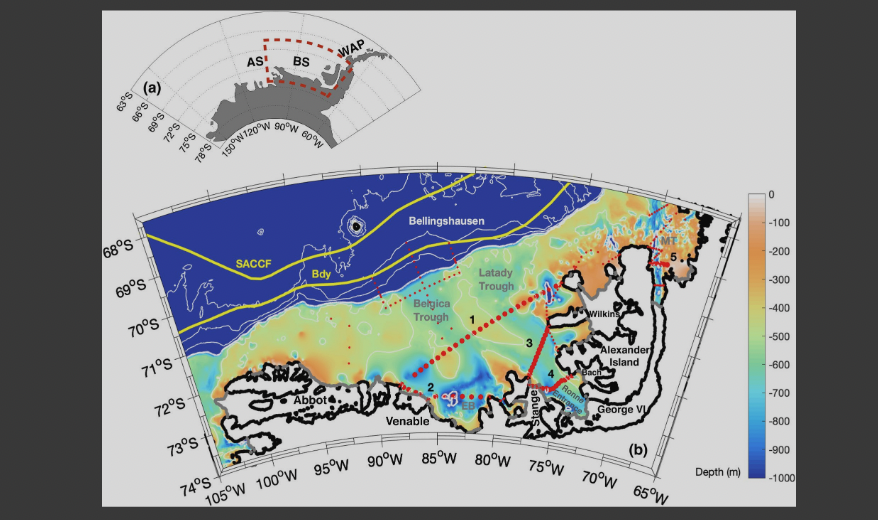

- research cruise carried out by the palmer Clark Ross in February and March of 2007 (JR165, Castro Morales et al., 2013)
- Hydrographic profiles were obtained using a Sea-Bird 911+ system (conductivity, temperature, and pressure), Sea-Bird SBE 3+ and SBE 4C sensors, and an SBE-43 dissolved oxygen sensor. Further calibration and processing of the data from the JR165 cruise were discussed by Castro-Morales et al. (2013).

### Sections 

section 1 
- A = [136 73 52 38 170];
- B = [161 85 68 51 176];

if section 3
    - A(3), B(3) 
    - stations 52 : 68 

section 2
- A = [73 80];
- B = [80 85];

- if section 2 
    A(2) B(2)
    80 : 85 

from map: 
- Section 1: 136: 161 
- Section 2: 73 : 85 
- (section 2 broken into two parts 73: 80, 80:85) 
- Section 3: 52 : 68 
- Section 4: 38: 51 
- Section 5: 170: 176 

PLOT SEC 1 LIKE PAPER 

/tmp/ipykernel_2924778/3748196773.py:33: RuntimeWarning: invalid value encountered in cast
  row_idx = np.round((real_pres) / dz).astype(int)   # nearest common-grid row for each real sample
/tmp/ipykernel_2924778/2914083854.py:36: RuntimeWarning: invalid value encountered in cast
  row_idx = np.round(np.real((real_pres - 1) / dz)).astype(int)   # nearest common-grid row for each real sample
/tmp/ipykernel_2924778/3748196773.py:33: RuntimeWarning: invalid value encountered in cast
  row_idx = np.round((real_pres) / dz).astype(int)   # nearest common-grid row for each real sample
/tmp/ipykernel_2924778/2914083854.py:36: RuntimeWarning: invalid value encountered in cast
  row_idx = np.round(np.real((real_pres - 1) / dz)).astype(int)   # nearest common-grid row for each real sample
/tmp/ipykernel_2924778/3748196773.py:33: RuntimeWarning: invalid value encountered in cast
  row_idx = np.round((real_pres) / dz).astype(int)   # nearest common-grid row for each real sample
/tmp/ipykernel_2924

inflow z>z_ref : 33.66 Sv
outflow z>z_ref : -31.83 Sv
net transport z>z_ref : 1.83 Sv
inflow all z: 33.66 Sv
outflow all z : -31.83 Sv
net transport all z : 1.83 Sv


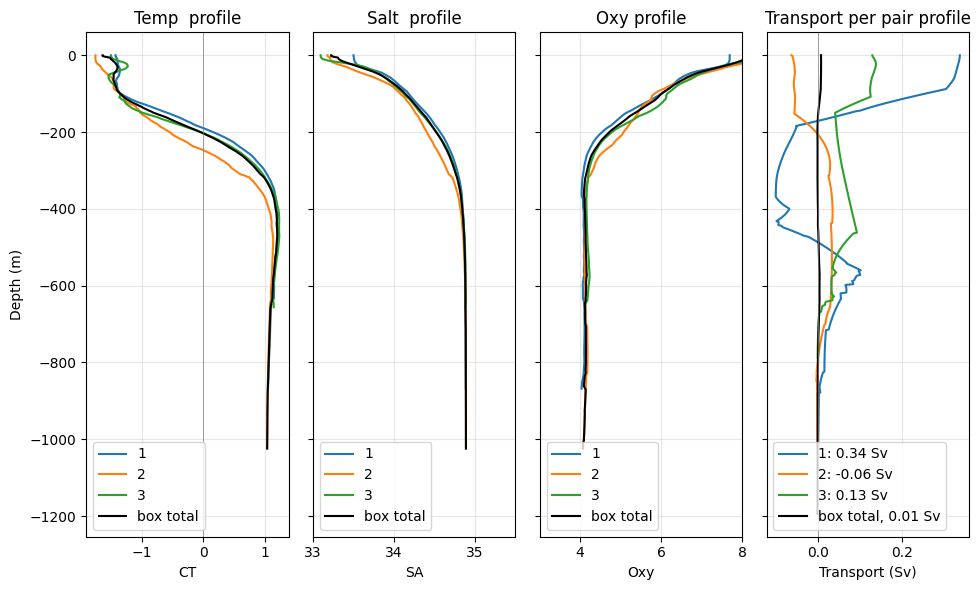

In [74]:
# full shelf box 

# A=(136, 73, 52, 38, 170)
# B=(161, 85, 68, 51, 176)

section1 = np.arange(136, 161, 1)
section2 = np.arange(73, 85, 1)
section3 = np.arange(52, 68, 1)
section4 = np.arange(38, 51, 1)
section5 = np.arange(170, 176, 1)

section1 = np.hstack([section1])
section2 = np.hstack([section2])
section3 = np.hstack([section3])
section4 = np.hstack([section4])
section5 = np.hstack([section5])


inflow_table = {1: {"latlon": "lat", "inflow": "south"},  # Shelf: box interior is south of this line
                2: {"latlon": "lat", "inflow": "north"},   # West: box interior is east of this boundary 
                3: {"latlon": "lat", "inflow": "north"},}

james_results = inverse_solver(james_ctd, sections = [section1, section2, section3], adj_table=ADJ_TABLE_5SECTION, extra_bumps=None, vel2_for_sec_nums=(1, ), dz = 2, ref_depth = 0, inflow_table = None)
james_results

james_pair_df = build_pair_df(james_results)

vertical_profile_subplots(james_pair_df, labels=["1", "2", "3"])
 # large box 




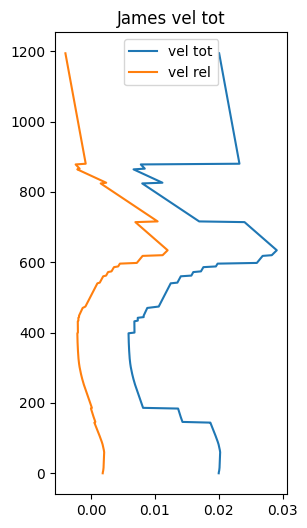

In [75]:
james_section0 = james_pair_df[james_pair_df["section"] == 0]
james_sect0_pres = james_section0.groupby('pres')["vel_tot"].mean().sort_index()

james_section1 = james_pair_df[james_pair_df["section"] == 0]
james_sect1_pres = james_section1.groupby('pres')["vel_rel"].mean().sort_index()


plt.figure(figsize = (3, 6))

plt.plot(james_sect0_pres, james_sect0_pres.index, label = "vel tot")
plt.plot(james_sect1_pres, james_sect1_pres.index, label = "vel rel")

plt.title("James vel tot")

# plt.gca().invert_yaxis()

plt.legend()

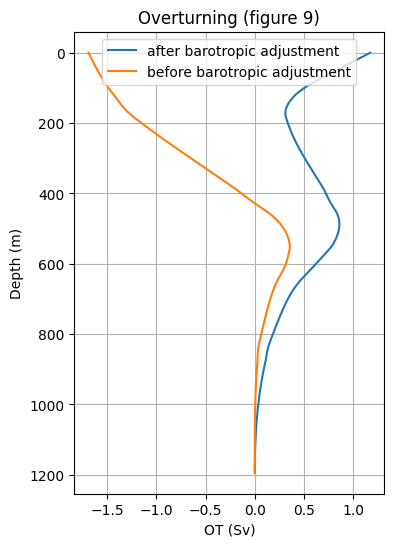

In [76]:
james_section0 = james_pair_df[james_pair_df["section"] == 0]
transport_adjustment_subplots(james_section0, labels=None)


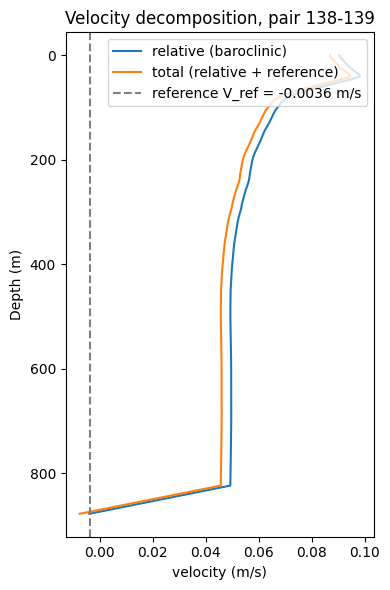

In [77]:
# Velocity decomposition vs depth, for one example station pair -- shows how the
# depth-constant reference/barotropic correction (V_ref) is added to the relative
# (baroclinic) velocity profile to get the total velocity, v_tot(z) = v_rel(z) + V_ref.
pair_idx = 2  # station pair 136-137

v_rel_profile = james_results["v_full_sec_list"][0][:, pair_idx]   # pre-V_ref, triangle-aware
v_tot_profile = james_results["V_full_sec_list"][0][:, pair_idx]   # post-V_ref, triangle-aware
v_ref_val = james_results["V_ref_sec_list"][0][pair_idx]
depth_axis = np.arange(0, len(v_rel_profile)) * 2  # dz=2 for the james/JR165 grid

plt.figure(figsize=(4, 6))
plt.plot(v_rel_profile, depth_axis, label="relative (baroclinic)")
plt.plot(v_tot_profile, depth_axis, label="total (relative + reference)")
plt.axvline(v_ref_val, color="gray", linestyle="--", label=f"reference V_ref = {v_ref_val:.4f} m/s")
plt.gca().invert_yaxis()
plt.title(f"Velocity decomposition, pair {section1[pair_idx]}-{section1[pair_idx+1]}")
plt.xlabel("velocity (m/s)")
plt.ylabel("Depth (m)")
plt.legend(loc = "upper right")
plt.tight_layout()


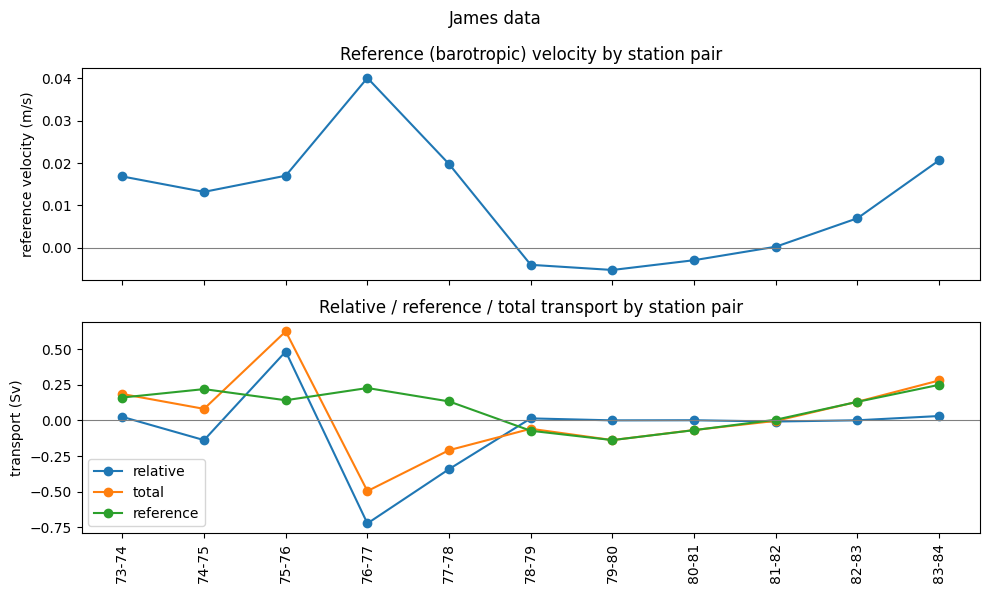

In [78]:
reference_vel_transport_bystation(james_results, section = 1, title = "James data")


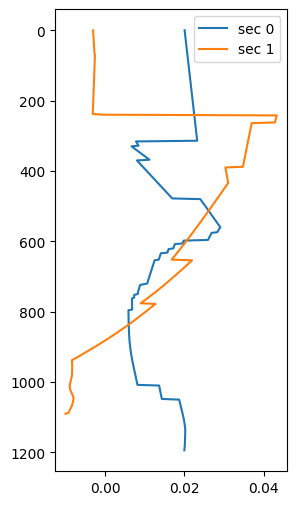

In [79]:
plt.figure(figsize = (3, 6))

james_section0 = james_pair_df[james_pair_df["section"] == 0]
james_sect0_pres = james_section0.groupby('pres')["vel_tot"].mean().sort_index()

james_section1 = james_pair_df[james_pair_df["section"] == 1]
james_sect1_pres = james_section1.groupby('pres')["vel_tot"].mean().sort_index()

plt.plot(james_sect0_pres, james_sect0_pres.index[::-1], label = "sec 0")
plt.plot(james_sect1_pres, james_sect1_pres.index[::-1], label = "sec 1")
plt.gca().invert_yaxis()
plt.legend()

# Palmer CTD Data 

### testing palmer sections

- I want to compare the transport estimates from the solved for inverse velocities with my hydrographic sections 
- I should be able to make the same plots for these figures as straight from my CTD data, just using the solved for velocities 

- start with section 115-120 as a test

In [80]:
# smoke test: same tracer_inverse/vel_inverse functions used for
# JR165 above, just pointed at the palmer data and an arbitrary small station range
palmer_station_list = np.arange(115, 121)  # stations 115-120

palmer_tracers = tracer_inverse(palmer_ctd, 1, dz=2, station_list=palmer_station_list)
print("new_CT shape:", palmer_tracers["new_CT"].shape)

# no hand-tuned calibration exists for this dataset yet -- zero offsets just runs the raw
# dynamic-method velocity with the deep-pair-bottom reference, no bias correction applied
palmer_adj_table = {1: {"vel2_offset": 0.0, "vel3_offset": 0.0, "high_count_src": "vel3", "low_count_src": "vel3"}}
palmer_vel = vel_inverse(palmer_ctd, 1, adj_table=palmer_adj_table, vel2_for_sec_nums=(1,), dz=1, station_list=palmer_station_list)

print("v shape:", palmer_vel["v"].shape)
print("v_tri:", palmer_vel["v_tri"])
print("v:", palmer_vel["v"][~np.isnan(palmer_vel["v"])])

new_CT shape: (2500, 5)
v shape: (5000, 5)
v_tri: [ 0.02623865 -0.01931001  0.00278686  0.00802684  0.33958271]
v: [ 0.03910845 -0.03631015  0.00735541 ...  0.00253458  0.00126735
  0.        ]


### palmer large box 

inflow z>z_ref : 13.69 Sv
outflow z>z_ref : -15.25 Sv
net transport z>z_ref : -1.56 Sv
inflow all z: 13.69 Sv
outflow all z : -15.25 Sv
net transport all z : -1.56 Sv


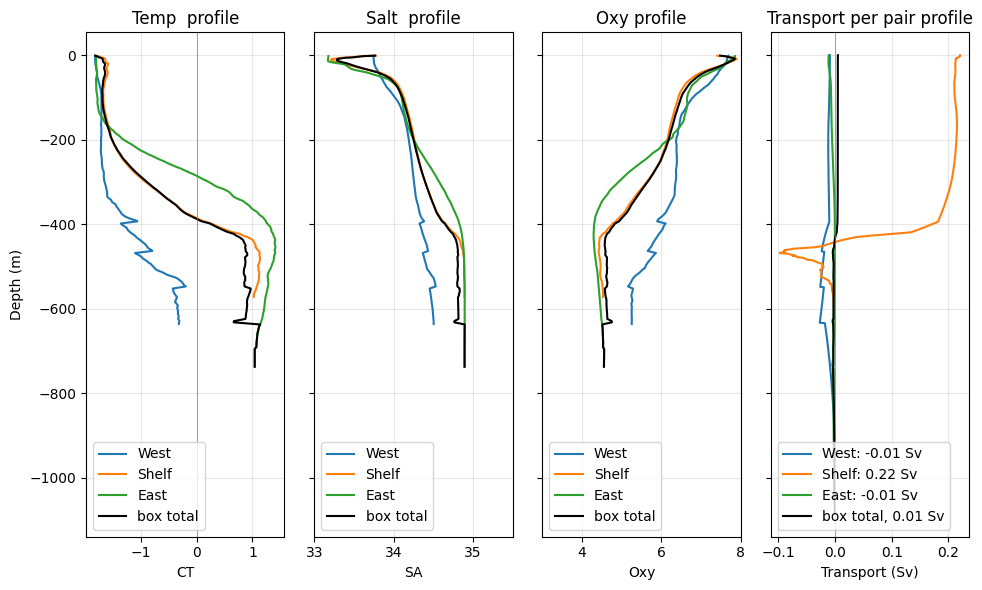

In [81]:
# full shelf box 
use_west = np.array([115, 116, 117, 118, 119, 120])
use_shelf = np.array([119, 122, 123, 125, 126, 127, 129, 131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])
use_east = np.array([160, 161, 162, 163, 164])

use_shelf = np.hstack([use_shelf])
use_west = np.hstack([use_west])
use_east = np.hstack([use_east])

labels = ["West", "Shelf",  "East"]
inflow = ["east", "south", "west"]
latlon = ["lat", "lon", "lat"]

palmer_largebox_results = inverse_solver(palmer_ctd, sections = [use_west, use_shelf, use_east], adj_table=None, extra_bumps=None, vel2_for_sec_nums=(1,), dz=1, ref_depth = 0, inflow_table = None)
palmer_largebox_df = build_pair_df(palmer_largebox_results)

vertical_profile_subplots(palmer_largebox_df, labels=["West", "Shelf", "East"])
 # large box 


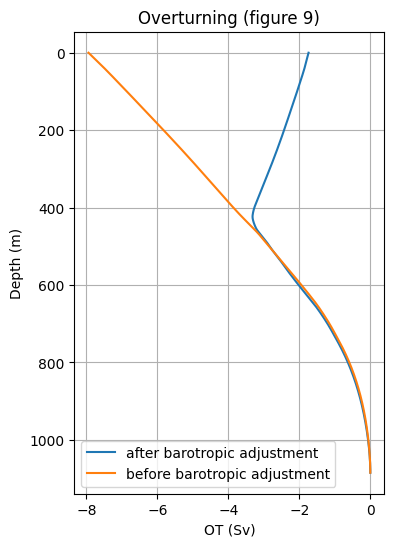

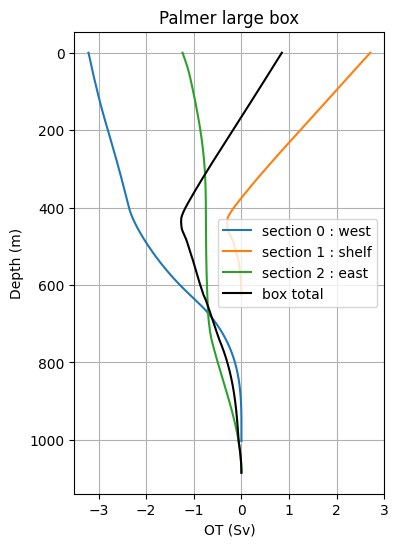

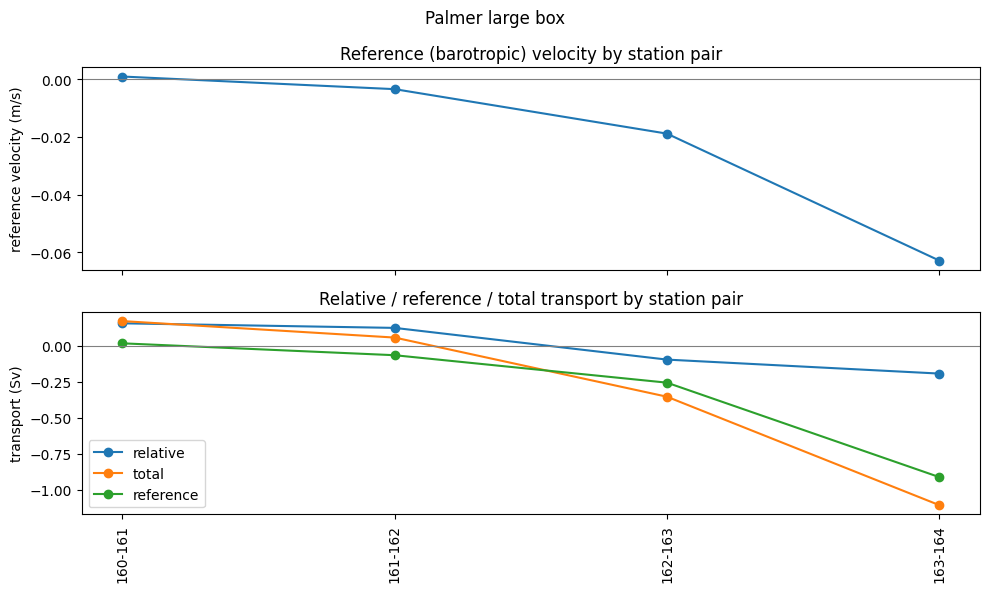

In [82]:
palmer_section0 = palmer_largebox_df[palmer_largebox_df.section == 2]
transport_adjustment_subplots(palmer_largebox_df, labels=None)
transport_sections_subplots(palmer_largebox_df, title = "Palmer large box")

reference_vel_transport_bystation(palmer_largebox_results, section = 2, title = "Palmer large box")



## palmer large box cross sections

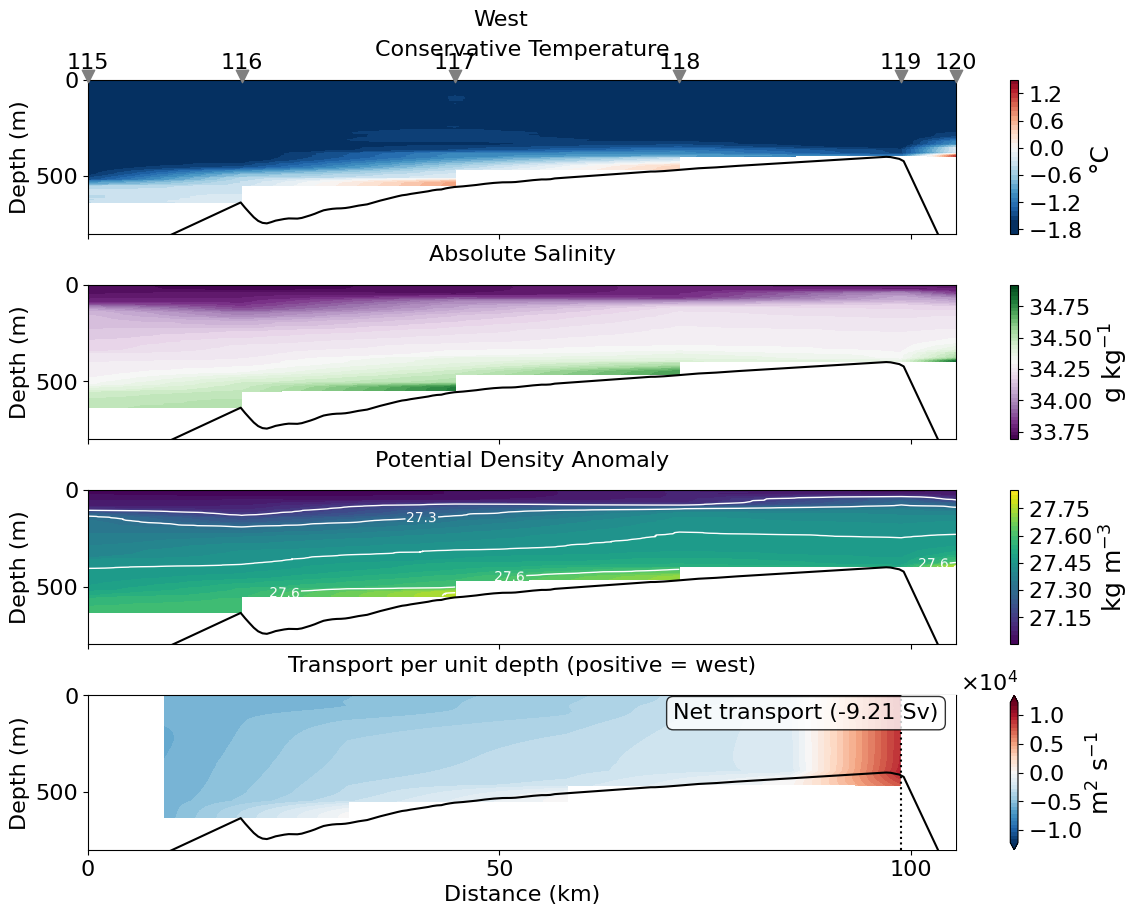

In [83]:
# smoke test for the adapted make_cross_sec_plots, now with real bathymetry + max_latlon
# (given here as a station number, matching Palmer_data_version3's cell 51: max_latlon = lat_119)
use_west_test = np.array([115, 116, 117, 118, 119, 120])
# max_latlon = (palmer_ctd[palmer_ctd.station == 119]["lat"].values[0] + palmer_ctd[palmer_ctd.station == 120]["lat"].values[0])/2
make_cross_sec_plots(palmer_ctd, use_west_test, latlon="lat", latlon_label="Latitude",
                      inflow="west", max_depth=800, title="West", dz=1,
                      x_axis="distance_km", max_latlon= 119)


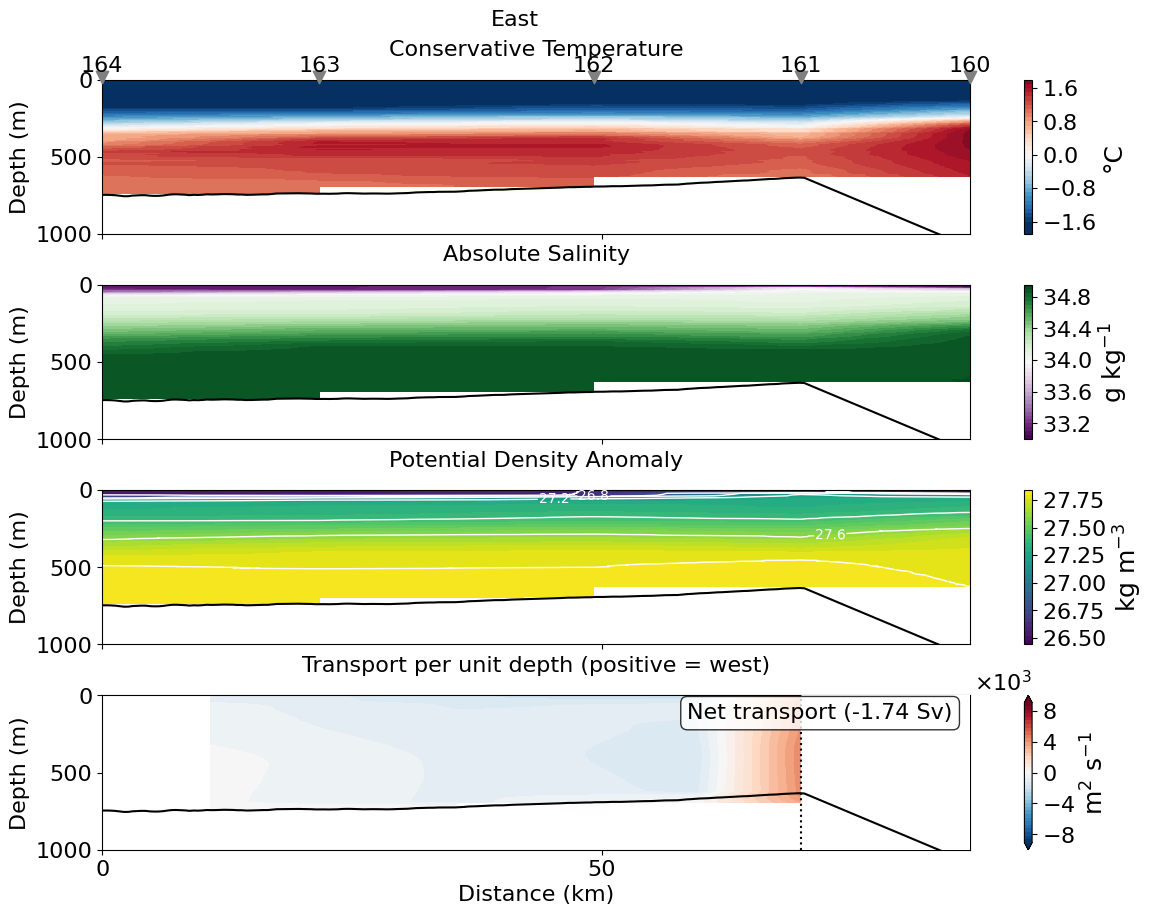

In [84]:
# smoke test for the adapted make_cross_sec_plots
use_east_test = np.array([164, 163, 162, 161, 160])

make_cross_sec_plots(palmer_ctd, use_east_test, latlon="lat", latlon_label="Latitude",
                      inflow="west", max_depth=1000, title="East", dz=1,
                      x_axis="distance_km", max_latlon= 161)

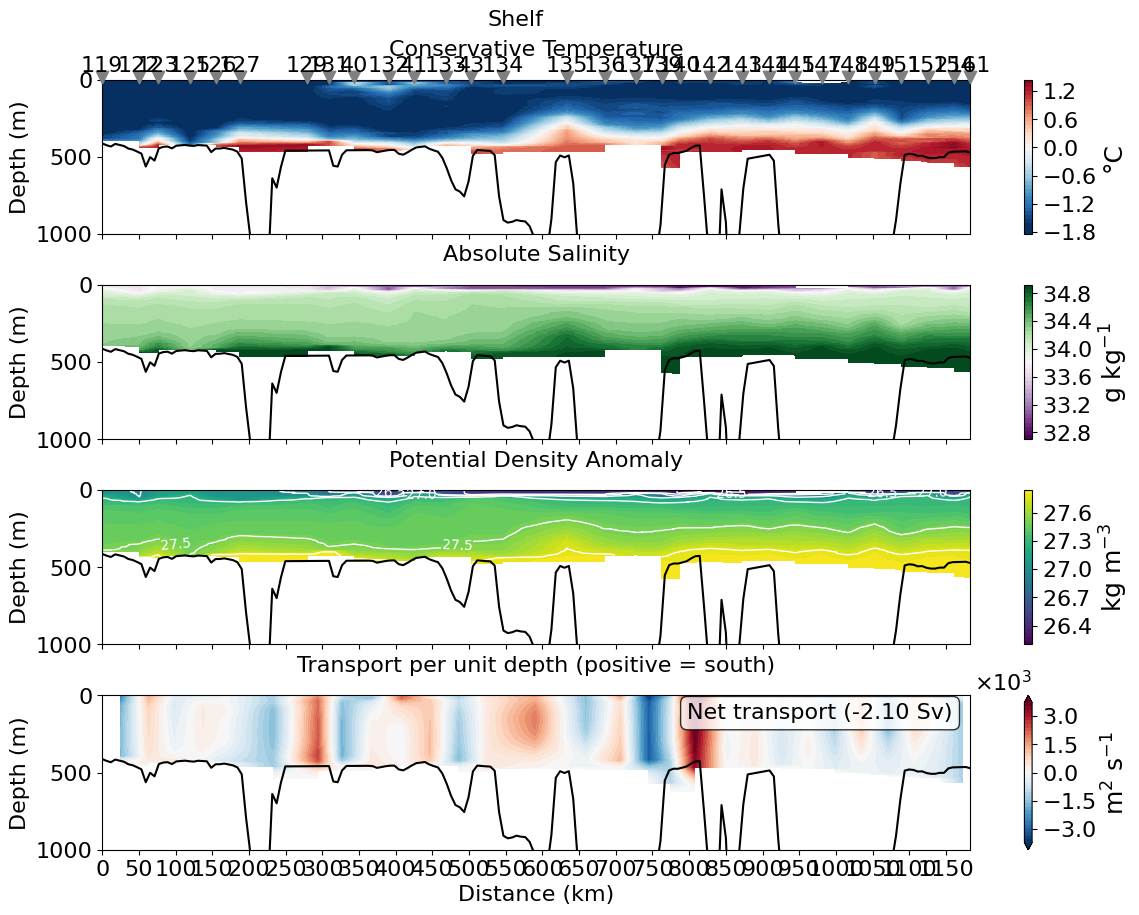

In [85]:
# smoke test for the adapted make_cross_sec_plots
use_shelf_test = np.array([119, 122, 123, 125, 126, 127, 129, 131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])

make_cross_sec_plots(palmer_ctd, use_shelf_test, latlon="lat", latlon_label="Latitude",
                      inflow="south", max_depth=1000, title="Shelf", dz=1,
                      x_axis="distance_km", max_latlon= None)

### palmer small box

inflow z>z_ref : 12.78 Sv
outflow z>z_ref : -14.78 Sv
net transport z>z_ref : -2.00 Sv
inflow all z: 12.78 Sv
outflow all z : -14.78 Sv
net transport all z : -2.00 Sv


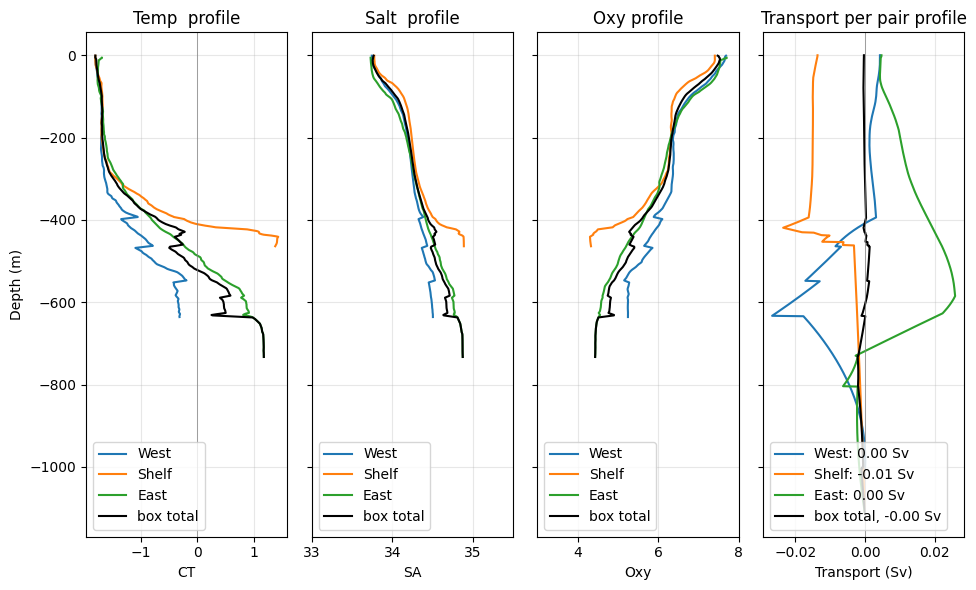

In [86]:
# small box 
use_west_box = np.array([115, 116, 117, 118, 119, 120])
use_shelf_box = np.array([119, 122, 123, 125, 126, 127, 99])
use_east_box = np.array([99, 100, 101, 102, 103])

use_west = np.hstack([use_west_box])
use_shelf = np.hstack([use_shelf_box])
use_east = np.hstack([use_east_box])

labels = ["West", "Shelf",  "East"]
inflow = ["east", "south", "west"]
latlon = ["lat", "lon", "lat"]

palmer_smallbox_results = inverse_solver(palmer_ctd, sections = [use_west, use_shelf, use_east], adj_table=None, extra_bumps=None, vel2_for_sec_nums=(1,), dz=1, ref_depth = 0, inflow_table = None)
palmer_smallbox_df = build_pair_df(palmer_smallbox_results)

vertical_profile_subplots(palmer_smallbox_df, labels=["West", "Shelf", "East"])

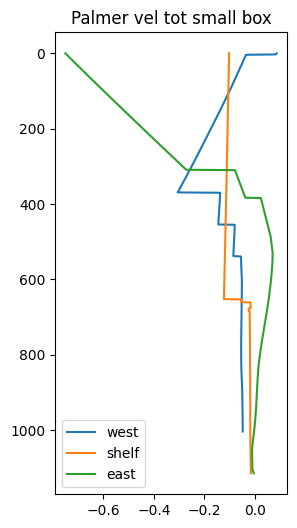

In [87]:
plt.figure(figsize = (3, 6))
palmer_section0 = palmer_smallbox_df[palmer_smallbox_df["section"] == 0]
palmer_sect0_pres = palmer_section0.groupby('pres')["vel_tot"].mean().sort_index()

palmer_section1 = palmer_smallbox_df[palmer_smallbox_df["section"] == 1]
palmer_sect1_pres = palmer_section1.groupby('pres')["vel_tot"].mean().sort_index()

palmer_section2 = palmer_smallbox_df[palmer_smallbox_df["section"] == 2]
palmer_sect2_pres = palmer_section2.groupby('pres')["vel_tot"].mean().sort_index()

plt.plot(palmer_sect0_pres, palmer_sect0_pres.index[::-1], label = "west")
plt.plot(palmer_sect1_pres, palmer_sect1_pres.index[::-1], label = "shelf")
plt.plot(palmer_sect2_pres, palmer_sect2_pres.index[::-1], label = "east")

plt.gca().invert_yaxis()
plt.title("Palmer vel tot small box")
plt.legend()

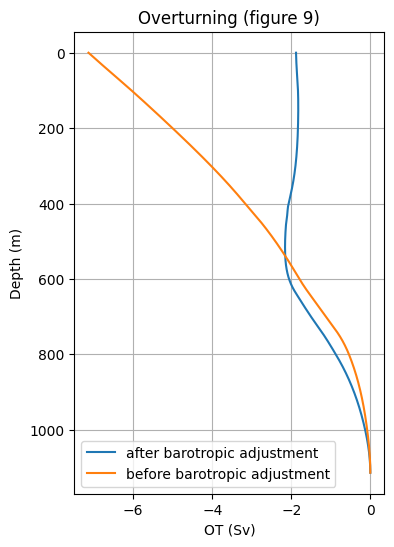

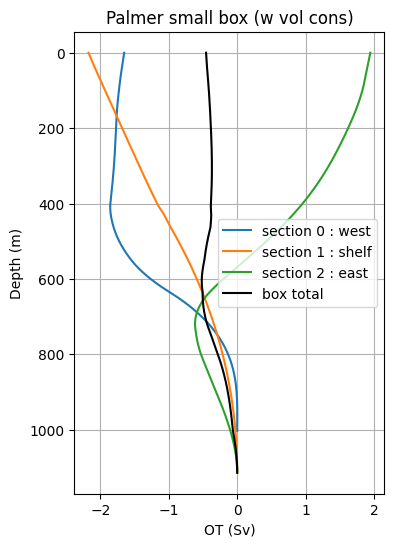

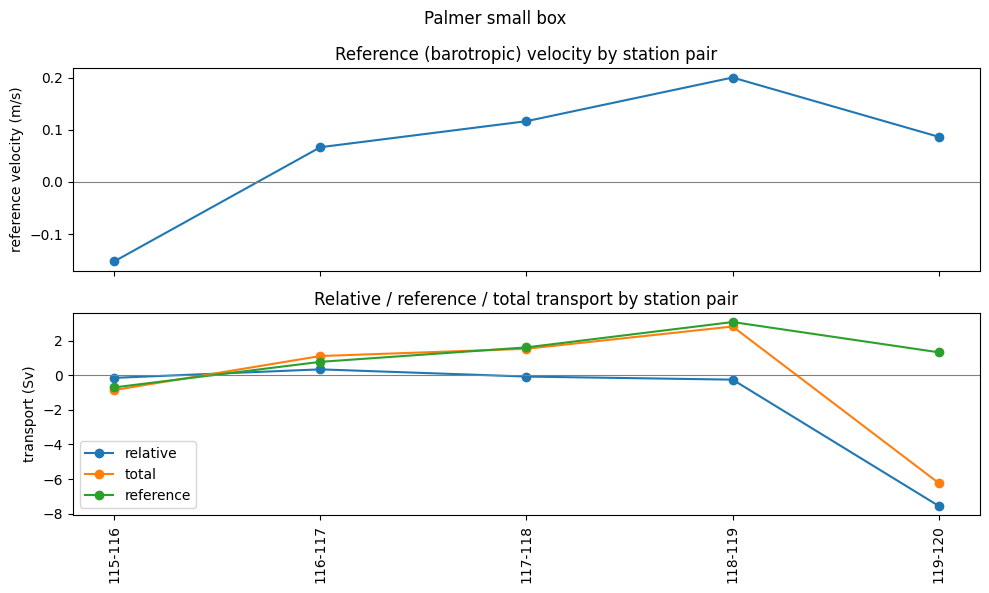

In [88]:
# palmer_section0 = palmer_smallbox_df[palmer_smallbox_df.section == 0]
transport_adjustment_subplots(palmer_smallbox_df, labels=None)
transport_sections_subplots(palmer_smallbox_df, title = "Palmer small box (w vol cons)")
reference_vel_transport_bystation(palmer_smallbox_results, title = "Palmer small box")
